# Calibration-Based Noise Estimator for Bug vs. Noise Attribution

Implementation of the technical specification *"Calibration-Based Noise Estimator for Bug vs. Noise Attribution"*.

**Goal.** Predict what a *correct* circuit should output on a given IBM device using only published calibration data
(gate errors, gate durations, T1, T2, asymmetric readout errors) and the hardware-transpiled circuit. Then compare the
observed output `P_obs` with the prediction `P_est`: a gap inside the normal estimator error means **noise**, a larger gap means **bug**.

**Validation-first.** Everything except the real-hardware section runs offline on *fake backends* (frozen IBM calibration snapshots shipped with
`qiskit_ibm_runtime`). The "observed" output `P_obs` comes from a full Aer density-matrix simulation built from the same
calibration (thermal relaxation on gates **and** idle periods, residual depolarizing, asymmetric readout). No QPU time is used.
The real-hardware section runs only when `RUN_HARDWARE = True`.

**Design choices**
* The estimator and the reference simulation use the **same hardware-transpiled circuit** `tqc = pm.run(qc)` that is sent to the device.
* The reference sets the depolarizing part of each gate to the error **left after** thermal relaxation, so decay is not counted twice.
* Readout uses the **real asymmetric** `prob_meas1_prep0` / `prob_meas0_prep1` of each physical qubit.
* Idle decay is modelled (ALAP schedule + relaxation on delays in the reference, idle-time term in the estimator).
* The bug threshold τ is **learned** from known-correct calibration circuits, not hand-picked.
* Distances use **TVD** (bounded, symmetric); KL and Hellinger are reported as secondary metrics.

## 0. Setup and configuration

Requirements: `qiskit>=2.0`, `qiskit-aer`, `qiskit-ibm-runtime` (fake backends + hardware), `numpy`, `pandas`, `matplotlib`.
On Kaggle/Colab uncomment the `%pip` line.

In [1]:
# %pip install -q qiskit qiskit-aer qiskit-ibm-runtime pandas matplotlib

import time
import math
import json
import zlib
import logging
import warnings
import datetime as dt
from dataclasses import dataclass, field
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import qiskit
import qiskit_aer
import qiskit_ibm_runtime
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import Delay
from qiskit.circuit.library import QuantumVolume
from qiskit.quantum_info import Statevector, DensityMatrix, random_clifford, average_gate_fidelity
from qiskit.transpiler import PassManager, InstructionDurations
from qiskit.transpiler.passes import ALAPScheduleAnalysis, PadDelay
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from qiskit_aer.noise import (NoiseModel, ReadoutError, depolarizing_error,
                              thermal_relaxation_error, RelaxationNoisePass)
from qiskit_ibm_runtime import fake_provider

warnings.filterwarnings("ignore", category=DeprecationWarning)
logging.basicConfig(level=logging.WARNING, format="%(levelname)s %(name)s: %(message)s")
log = logging.getLogger("noise-estimator")
logging.getLogger("qiskit_aer").setLevel(logging.ERROR)   # silence "noise model basis gates is empty" for readout-only models

print(f"qiskit {qiskit.__version__} | qiskit-aer {qiskit_aer.__version__} | qiskit-ibm-runtime {qiskit_ibm_runtime.__version__}")

qiskit 2.6.1 | qiskit-aer 0.18.2 | qiskit-ibm-runtime 0.51.0


In [2]:
# ── Experiment configuration ────────────────────────────────────────────────
# Every random choice (transpiler, simulator, bug placement) derives from SEED,
# so re-running the notebook reproduces the same numbers (spec §7 rule 4).
CONFIG = dict(
    backends        = ["FakeBrisbane", "FakeTorino"],  # ECR-based Eagle and CZ-based Heron snapshots
    shots           = 8192,       # spec §7 rule 5: >= 8192 shots
    seed            = 2026,
    opt_level       = 1,          # preset pass manager, light optimisation
    tau_quantile    = 0.95,       # τ = 95th percentile of correct-circuit gaps (spec §5)
    bug_instances   = 2,          # random placements per bug operator per circuit
    angle_delta     = 0.15,       # radians added by the "wrong angle" bug
    observable_tvd  = 0.05,       # a bug is "observable" in a basis if it moves the ideal output by > this TVD
    noise_scales    = [0.5, 1.0, 2.0, 4.0],  # RQ3: multiply all error rates (and 1/T1, 1/T2) by this factor
    rq3_backend     = "FakeBrisbane",
)
RUN_HARDWARE = False   # ⚠ True = Section 14 submits a real job (uses QPU time). Approved run is recorded in Section 14.

SHOTS = CONFIG["shots"]
SEED  = CONFIG["seed"]
rng_global = np.random.default_rng(SEED)

# Plot styling: thin marks, recessive grid, fixed categorical order (blue, orange, aqua) + neutral gray for baselines.
C_BLUE, C_ORANGE, C_AQUA, C_GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8c8b85"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.edgecolor": "#8c8b85", "axes.labelcolor": "#2b2b2b", "lines.linewidth": 2,
    "legend.frameon": False, "font.size": 9,
})

## 1. Calibration reader

Reads, for every physical qubit and gate of the backend:

| Symbol | Meaning | Source |
|---|---|---|
| ε_g, d_g | gate error and duration | `backend.target[name][qubits].error / .duration` |
| T1_q, T2_q | relaxation / dephasing times | `backend.qubit_properties(q)` |
| p_q(1\|0), p_q(0\|1) | asymmetric readout misassignment | `backend.properties()` → `prob_meas1_prep0`, `prob_meas0_prep1` |

Reading calibration is a metadata call and does **not** consume QPU quota. Missing T1/T2 values fall back to the backend
median (logged). The calibration timestamp is stored so every result can be traced to the calibration it used (spec §7 rule 4).
`Calibration.scaled(s)` multiplies all error rates by `s` (and divides T1, T2 by `s`) to emulate noisier/cleaner devices for RQ3.

In [3]:
NON_GATES = {"barrier", "delay", "measure", "reset"}   # never contribute a gate-error factor
CONTROL_FLOW = {"if_else", "for_loop", "while_loop", "switch_case", "box"}


@dataclass
class Calibration:
    """Snapshot of the calibration data needed by the estimator and the Aer reference."""
    backend_name: str
    timestamp: str                     # calibration timestamp reported by the backend
    dt: float                          # sample time (s), used for Delay instructions
    num_qubits: int
    gates: dict                        # (name, qubits) -> (error, duration_seconds)
    t1: dict                           # qubit -> T1 (s)
    t2: dict                           # qubit -> T2 (s)
    p10: dict                          # qubit -> P(measure 1 | prepared 0)
    p01: dict                          # qubit -> P(measure 0 | prepared 1)
    scale: float = 1.0                 # noise scale factor (1.0 = real calibration)
    notes: list = field(default_factory=list)

    def gate(self, name, qubits):
        """Return (error, duration) of a gate on specific physical qubits. Raises if the device does not calibrate it."""
        key = (name, tuple(qubits))
        if key not in self.gates:
            raise KeyError(f"No calibration for gate {name} on qubits {tuple(qubits)} ({self.backend_name})")
        return self.gates[key]

    def scaled(self, s):
        """Copy with every error rate multiplied by s and coherence times divided by s (durations unchanged)."""
        if s == 1.0:
            return self
        clip = lambda x, hi: float(min(max(x, 0.0), hi))
        return Calibration(
            backend_name=self.backend_name, timestamp=self.timestamp, dt=self.dt, num_qubits=self.num_qubits,
            gates={k: (clip(e * s, 0.5), d) for k, (e, d) in self.gates.items()},
            t1={q: v / s for q, v in self.t1.items()},
            t2={q: v / s for q, v in self.t2.items()},
            p10={q: clip(v * s, 0.5) for q, v in self.p10.items()},
            p01={q: clip(v * s, 0.5) for q, v in self.p01.items()},
            scale=self.scale * s, notes=list(self.notes),
        )

    def summary(self, qubits):
        """Per-qubit calibration table for the given physical qubits."""
        rows = []
        for q in qubits:
            sx_err, sx_dur = self.gates.get(("sx", (q,)), (np.nan, np.nan))
            rows.append({"qubit": q, "T1 (µs)": self.t1[q] * 1e6, "T2 (µs)": self.t2[q] * 1e6,
                         "sx err": sx_err, "sx dur (ns)": sx_dur * 1e9,
                         "P(1|0)": self.p10[q], "P(0|1)": self.p01[q]})
        return pd.DataFrame(rows).set_index("qubit")


def read_calibration(backend):
    """Build a Calibration from a (fake or real) IBM backend. No job is submitted."""
    target, notes = backend.target, []
    n = backend.num_qubits

    # Gate errors and durations straight from the Target (virtual rz has error 0 and duration 0).
    gates = {}
    for name in target.operation_names:
        if name in CONTROL_FLOW:
            continue
        for qargs, props in target[name].items():
            if qargs is None or props is None:
                continue
            gates[(name, tuple(qargs))] = (float(props.error or 0.0), float(props.duration or 0.0))

    # T1 / T2 per qubit; missing values -> backend median (logged).
    t1, t2 = {}, {}
    for q in range(n):
        qp = backend.qubit_properties(q)
        t1[q] = getattr(qp, "t1", None) if qp is not None else None
        t2[q] = getattr(qp, "t2", None) if qp is not None else None
    for name, d in (("T1", t1), ("T2", t2)):
        known = [v for v in d.values() if v]
        med = float(np.median(known))
        missing = [q for q, v in d.items() if not v]
        for q in missing:
            d[q] = med
        if missing:
            notes.append(f"{name} missing on {len(missing)} qubits -> median {med*1e6:.1f} µs")

    # Asymmetric readout from BackendProperties; fallback = symmetric measure error from the Target.
    p10, p01, timestamp = {}, {}, None
    props = None
    try:
        props = backend.properties()
    except Exception as exc:                       # some backends do not expose properties()
        notes.append(f"properties() unavailable: {exc}")
    if props is not None:
        timestamp = props.last_update_date.isoformat() if props.last_update_date else None
    for q in range(n):
        a = b = None
        if props is not None:
            try:
                qprops = props.qubit_property(q)
                a = qprops.get("prob_meas1_prep0", (None,))[0]
                b = qprops.get("prob_meas0_prep1", (None,))[0]
            except Exception:
                pass
        if a is None or b is None:
            sym = gates.get(("measure", (q,)), (0.0, 0.0))[0]
            a, b = sym, sym
            notes.append(f"q{q}: asymmetric readout missing, using symmetric {sym:.4f}")
        p10[q], p01[q] = float(a), float(b)

    cal = Calibration(backend_name=backend.name, timestamp=timestamp or dt.datetime.now(dt.timezone.utc).isoformat(),
                      dt=float(target.dt or 0.0), num_qubits=n, gates=gates, t1=t1, t2=t2, p10=p10, p01=p01, notes=notes)
    for msg in notes[:5]:
        log.info(msg)
    return cal


def save_calibration(cal, path):
    """Cache a calibration snapshot (with its timestamp) as JSON, e.g. to re-use the exact numbers of a hardware run."""
    d = {k: v for k, v in cal.__dict__.items() if k not in ("gates", "t1", "t2", "p10", "p01")}
    d["gates"] = [[n, list(q), e, du] for (n, q), (e, du) in cal.gates.items()]
    for k in ("t1", "t2", "p10", "p01"):
        d[k] = {str(q): v for q, v in getattr(cal, k).items()}
    d["saved_at"] = dt.datetime.now(dt.timezone.utc).isoformat()
    with open(path, "w") as fh:
        json.dump(d, fh)


def load_calibration(path):
    with open(path) as fh:
        d = json.load(fh)
    d.pop("saved_at", None)
    d["gates"] = {(n, tuple(q)): (e, du) for n, q, e, du in d["gates"]}
    for k in ("t1", "t2", "p10", "p01"):
        d[k] = {int(q): v for q, v in d[k].items()}
    return Calibration(**d)


def load_fake_backend(name):
    """Offline backend from qiskit_ibm_runtime.fake_provider, e.g. 'FakeBrisbane'."""
    return getattr(fake_provider, name)()


def make_pass_manager(backend):
    """Preset pass manager for the backend, with a fixed transpiler seed."""
    return generate_preset_pass_manager(backend=backend, optimization_level=CONFIG["opt_level"],
                                        seed_transpiler=SEED)


BACKENDS, CALIBS, PMS = {}, {}, {}
for bname in CONFIG["backends"]:
    BACKENDS[bname] = load_fake_backend(bname)
    CALIBS[bname] = read_calibration(BACKENDS[bname])
    PMS[bname] = make_pass_manager(BACKENDS[bname])
    c = CALIBS[bname]
    basis = sorted({k[0] for k in c.gates} - NON_GATES)
    print(f"{c.backend_name:15s} {c.num_qubits:4d} qubits | basis {basis} | calibration {c.timestamp} | notes: {len(c.notes)}")

fake_brisbane    127 qubits | basis ['ecr', 'id', 'rz', 'sx', 'x'] | calibration 2025-02-26T14:33:06-05:00 | notes: 0
fake_torino      133 qubits | basis ['cz', 'id', 'rz', 'sx', 'x'] | calibration 2025-02-26T15:26:08-05:00 | notes: 0


## 2. Circuit helpers and per-qubit idle time

* `compact_circuit` strips the idle wires of a 100+ qubit transpiled circuit down to the active physical qubits
  (the gates, layout and basis are untouched; it is still `tqc`).
* `measured_qubits` maps each classical bit to the physical qubit measured into it (the final layout is already applied in `tqc`).
* `idle_times` computes `t_q` from calibrated gate durations with an **ALAP** schedule, which is how IBM schedules jobs
  (barriers take no time but synchronise their qubits, as on the device).
  A qubit is only counted as idle inside its *active window* (from its first operation to the end of the circuit): before its
  first gate the qubit sits in |0⟩, where neither T1 decay nor dephasing changes anything. `mode="total"` reproduces the spec
  sketch (total time − busy time) for comparison. Measurements count as busy (decay during readout is part of the readout error).

In [4]:
def _qidx(circ, bits):
    return [circ.find_bit(b).index for b in bits]


def compact_circuit(tqc):
    """Return (circuit on k active qubits, list of their physical indices). Barriers are kept on the active qubits."""
    active = sorted({q for inst in tqc.data if inst.operation.name not in ("barrier", "delay")
                     for q in _qidx(tqc, inst.qubits)})
    pos = {p: i for i, p in enumerate(active)}
    out = QuantumCircuit(len(active), tqc.num_clbits, global_phase=tqc.global_phase)
    for inst in tqc.data:
        qs = _qidx(tqc, inst.qubits)
        if inst.operation.name == "barrier":
            keep = [pos[q] for q in qs if q in pos]
            if keep:
                out.barrier(keep)
            continue
        if any(q not in pos for q in qs):          # delay on an unused wire
            continue
        out.append(inst.operation, [pos[q] for q in qs], _qidx(tqc, inst.clbits))
    return out, active


def measured_qubits(circ):
    """List q_k = qubit measured into classical bit k (last measurement wins)."""
    m = {}
    for inst in circ.data:
        if inst.operation.name == "measure":
            m[_qidx(circ, inst.clbits)[0]] = _qidx(circ, inst.qubits)[0]
    missing = [k for k in range(circ.num_clbits) if k not in m]
    if missing:
        raise ValueError(f"classical bits {missing} are never measured")
    return [m[k] for k in range(circ.num_clbits)]


def instruction_duration(inst, phys, calib):
    """Duration in seconds of one instruction of a compact circuit (phys maps compact -> physical)."""
    op = inst.operation
    if op.name == "delay":
        return float(op.duration) * (calib.dt if op.unit == "dt" else 1.0)
    return calib.gate(op.name, phys)[1]


def idle_times(cqc, phys, calib, mode="window"):
    """
    Per-qubit idle time t_q (seconds) of a compact circuit under an ALAP schedule.
      mode="window": idle inside [first operation, end of circuit]  (default, see markdown above)
      mode="total" : total circuit time − busy time                 (spec §7 sketch)
    Returns (idle dict keyed by compact index, total circuit duration).
    """
    ops = []
    for inst in cqc.data:
        qs = _qidx(cqc, inst.qubits)
        dur = 0.0 if inst.operation.name == "barrier" else instruction_duration(inst, [phys[q] for q in qs], calib)
        ops.append((inst.operation.name, qs, dur))          # barriers: zero length, but synchronise their qubits

    # ALAP: schedule the reversed circuit ASAP, measuring time backwards from the end.
    tail = defaultdict(float)
    intervals = []
    for name, qs, dur in reversed(ops):
        start_from_end = max(tail[q] for q in qs)
        for q in qs:
            tail[q] = start_from_end + dur
        intervals.append((name, qs, start_from_end, dur))
    total = max(tail.values()) if tail else 0.0

    first_start, busy = {}, defaultdict(float)
    for name, qs, s_end, dur in intervals:
        start = total - (s_end + dur)
        for q in qs:
            if name in ("delay", "barrier"):
                continue
            first_start[q] = min(first_start.get(q, np.inf), start)
            busy[q] += dur
    idle = {}
    for q in range(cqc.num_qubits):
        if q not in first_start:
            continue
        window = total - first_start[q] if mode == "window" else total
        idle[q] = max(window - busy[q], 0.0)
    return idle, total

## 3. The lightweight estimator (spec §4)

**Step 1 – pure dephasing.** $1/T_{\phi,q} = 1/T_{2,q} - 1/(2T_{1,q})$, with $T_2$ clipped to $2T_1$.

**Step 2 – circuit fidelity (ESP).** $F = \prod_{g\in C}(1-\varepsilon_g)\cdot\prod_q e^{-t_q/T_{1,q}}e^{-t_q/T_{\phi,q}}$,
summed in log space. Barriers, delays, measurements, resets and virtual `rz` contribute no gate factor.

**Step 3 – global depolarizing.** $P_{gate} = F\,P_{ideal} + (1-F)/2^n$.

**Step 4 – asymmetric readout.** $P_{est} = (\bigotimes_q M_q)\,P_{gate}$, applied one qubit at a time on a reshaped tensor
(classical bit 0 = right-most bit = last tensor axis).

**Which `P_ideal`?** In testing, the program under test may be buggy, so `P_ideal` is the *expected* (specification)
distribution, i.e. the noiseless output of the correct program, while `F` and the readout matrices come from the
transpiled circuit **that is actually executed**. For a correct program these coincide with spec §3.

In [5]:
def ideal_distribution(qc):
    """
    Exact noiseless distribution over the classical bits of a circuit whose measurements are terminal.
    Index convention = Qiskit little-endian: classical bit k is bit k of the integer index.
    Supports reset (density-matrix evolution); a 30-qubit statevector is the practical limit (spec §6).
    """
    meas = {}
    body = QuantumCircuit(qc.num_qubits, global_phase=qc.global_phase)
    for inst in qc.data:
        name, qs = inst.operation.name, _qidx(qc, inst.qubits)
        if name == "measure":
            meas[_qidx(qc, inst.clbits)[0]] = qs[0]
            continue
        if name in ("barrier", "delay"):
            continue
        if any(q in meas.values() for q in qs):
            raise ValueError("ideal_distribution requires terminal measurements")
        body.append(inst.operation, qs)
    qargs = [meas[k] for k in range(qc.num_clbits)]
    state = DensityMatrix(body) if "reset" in body.count_ops() else Statevector(body)
    return np.asarray(state.probabilities(qargs), dtype=float)


def pure_dephasing_rate(T1, T2):
    """Step 1: 1/T_phi with the physical clip T2 <= 2*T1 (returns 0 when T2 = 2*T1)."""
    T2 = min(T2, 2.0 * T1)
    return max(1.0 / T2 - 1.0 / (2.0 * T1), 0.0)


def circuit_fidelity(cqc, phys, calib, idle_mode="window"):
    """Step 2: F = gate-success product × idle-decay product (log-space). Returns (F, F_gates, F_idle, idle)."""
    log_gates = 0.0
    for inst in cqc.data:
        name = inst.operation.name
        if name in NON_GATES:
            continue
        eps, _ = calib.gate(name, [phys[q] for q in _qidx(cqc, inst.qubits)])
        log_gates += math.log1p(-min(eps, 1 - 1e-12))
    idle, _ = idle_times(cqc, phys, calib, mode=idle_mode)
    log_idle = 0.0
    for q, tq in idle.items():
        T1 = calib.t1[phys[q]]
        log_idle += -tq / T1 - tq * pure_dephasing_rate(T1, calib.t2[phys[q]])
    return math.exp(log_gates + log_idle), math.exp(log_gates), math.exp(log_idle), idle


def apply_readout(p, meas_phys, p10, p01):
    """Step 4: apply per-qubit 2x2 confusion matrices without building the 2^n x 2^n matrix."""
    n = len(meas_phys)
    t = np.asarray(p, dtype=float).reshape([2] * n)       # axis 0 = most significant bit = classical bit n-1
    for k, q in enumerate(meas_phys):                     # k = classical bit index
        M = np.array([[1 - p10[q], p01[q]],
                      [p10[q], 1 - p01[q]]])              # column = prepared, row = measured
        axis = n - 1 - k
        t = np.moveaxis(np.tensordot(M, t, axes=([1], [axis])), 0, axis)
    return t.reshape(-1)


@dataclass
class Estimate:
    p_est: np.ndarray        # Step 4 output (prediction for a correct program)
    p_gate: np.ndarray       # Step 3 output (before readout)
    F: float
    F_gates: float
    F_idle: float
    meas_phys: list          # physical qubit per classical bit
    active_phys: list
    n_2q: int
    depth: int
    seconds: float           # estimator wall-clock time


def estimate(p_spec, tqc, calib, idle_mode="window"):
    """Steps 1-4 for one hardware-transpiled circuit. p_spec = expected (ideal) distribution of the correct program."""
    t0 = time.perf_counter()
    cqc, active = compact_circuit(tqc)
    meas_phys = [active[q] for q in measured_qubits(cqc)]
    F, Fg, Fi, _ = circuit_fidelity(cqc, active, calib, idle_mode)
    n = len(meas_phys)
    p_gate = F * np.asarray(p_spec) + (1 - F) / 2 ** n
    p_est = apply_readout(p_gate, meas_phys, calib.p10, calib.p01)
    secs = time.perf_counter() - t0
    n_2q = sum(1 for i in cqc.data if len(i.qubits) == 2 and i.operation.name not in NON_GATES)
    return Estimate(p_est, p_gate, F, Fg, Fi, meas_phys, active, n_2q, cqc.depth(), secs)

## 4. Distance metrics

* **TVD** (primary): $\tfrac12\sum_x|P(x)-Q(x)|$, bounded in [0, 1] and symmetric.
* **Hellinger**: $\sqrt{1-\sum_x\sqrt{P(x)Q(x)}}$.
* **KL** with a fixed ε = 1e-10 (secondary only: unbounded and asymmetric).
* **Shot-noise floor.** The spec's rough bound $\sqrt{2^n/\text{shots}}$, and the sharper expected TVD between a
  distribution and its own `shots`-sample estimate, $\mathbb E[\text{TVD}] \approx \tfrac12\sum_x\sqrt{2p_x(1-p_x)/(\pi N)}$ (normal approximation).

In [6]:
def tvd(p, q):
    return 0.5 * float(np.abs(np.asarray(p) - np.asarray(q)).sum())


def hellinger(p, q):
    bc = float(np.sum(np.sqrt(np.clip(p, 0, None) * np.clip(q, 0, None))))
    return math.sqrt(max(1.0 - bc, 0.0))


def kl_divergence(p, q, epsilon=1e-10):
    """KL(P || Q) with a small fixed epsilon added before normalising."""
    p = np.asarray(p, float) + epsilon
    q = np.asarray(q, float) + epsilon
    p, q = p / p.sum(), q / q.sum()
    return float(np.sum(p * np.log(p / q)))


def uniform(n):
    return np.full(2 ** n, 1.0 / 2 ** n)


def shot_floor_bound(n, shots):
    """Spec §5 rough bound sqrt(2^n / shots)."""
    return math.sqrt(2 ** n / shots)


def expected_shot_tvd(p, shots):
    """Expected TVD between p and an empirical estimate from `shots` samples (normal approximation)."""
    p = np.asarray(p, float)
    return 0.5 * float(np.sum(np.sqrt(2 * p * (1 - p) / (math.pi * shots))))


def counts_to_probs(counts, n):
    """Counts dict -> probability vector (little-endian, spaces between registers removed)."""
    v = np.zeros(2 ** n)
    total = sum(counts.values())
    for b, c in counts.items():
        v[int(b.replace(" ", ""), 2)] += c / total
    return v

## 5. Full Aer noisy reference

Used **only for validation**, it plays the role of "hardware" while we work offline. Built from the same `Calibration`:

1. The **same** transpiled circuit `tqc` is compacted, then ALAP-scheduled with the calibrated gate durations; idle periods
   become explicit `Delay`s.
2. Every delay receives a **thermal-relaxation** channel (T1, T2) via `RelaxationNoisePass`.
3. Every physical gate `g` on its physical qubits receives thermal relaxation over `d_g`, composed with a depolarizing channel
   whose strength is the gate error **left after** relaxation (so the total average gate infidelity equals the reported ε_g, no double counting).
   *Caveat:* on some qubits the reported T1/T2 alone already imply more error than the reported ε_g (about 30% of FakeBrisbane's gates,
   2% of FakeTorino's). Then no depolarizing part is added and relaxation alone is used, which is the same convention as Aer's
   `NoiseModel.from_backend`. For those gates the reference is slightly noisier than ε_g.
4. Measurements receive the **asymmetric** per-qubit readout error.

`reference_distribution(..., shots=None)` returns exact probabilities (density matrix + exact readout), and `shots=N`
samples like the hardware would.

In [7]:
def residual_depolarizing(eps, relax_err, n_qubits):
    """Depolarizing channel making the composite average gate infidelity equal to eps (same algebra as Aer's device model)."""
    dim = 2 ** n_qubits
    relax_fid = average_gate_fidelity(relax_err) if relax_err is not None else 1.0
    relax_infid = 1.0 - relax_fid
    if eps <= relax_infid:
        return None                                    # relaxation alone already explains the gate error
    eps = min(eps, dim / (dim + 1))
    param = dim * (eps - relax_infid) / (dim * relax_fid - 1)
    param = min(param, 4 ** n_qubits / (4 ** n_qubits - 1))
    return depolarizing_error(param, n_qubits)


def _thermal(calib, q, duration):
    T1 = calib.t1[q]
    T2 = min(calib.t2[q], 2 * T1)
    return thermal_relaxation_error(T1, T2, duration)


def build_reference_noise_model(cqc, phys, calib):
    """Noise model on the compact circuit's qubits (compact index i = physical qubit phys[i])."""
    skip = NON_GATES | {"quantum_channel"}           # relaxation channels inserted on delays are already noise
    nm = NoiseModel(basis_gates=sorted({i.operation.name for i in cqc.data} - skip))
    done = set()
    for inst in cqc.data:
        name, qs = inst.operation.name, tuple(_qidx(cqc, inst.qubits))
        if name in skip or (name, qs) in done:
            continue
        done.add((name, qs))
        eps, dur = calib.gate(name, [phys[q] for q in qs])
        if eps == 0.0 and dur == 0.0:                 # virtual rz
            continue
        relax = None
        if dur > 0:
            relax = _thermal(calib, phys[qs[0]], dur)
            for q in qs[1:]:
                relax = relax.expand(_thermal(calib, phys[q], dur))   # tensor order matches qargs order
        depol = residual_depolarizing(eps, relax, len(qs))
        err = relax.compose(depol) if (relax is not None and depol is not None) else (relax or depol)
        if err is not None:
            nm.add_quantum_error(err, name, list(qs))
    for q in range(cqc.num_qubits):
        a, b = calib.p10[phys[q]], calib.p01[phys[q]]
        nm.add_readout_error(ReadoutError([[1 - a, a], [b, 1 - b]]), [q])
    return nm


def scheduled_noisy_circuit(tqc, calib):
    """Compact + ALAP schedule + relaxation channels on idle delays. Returns (circuit, active physical qubits)."""
    cqc, phys = compact_circuit(tqc)
    seen, entries = set(), []
    for inst in cqc.data:
        name, qs = inst.operation.name, tuple(_qidx(cqc, inst.qubits))
        if name in ("delay", "barrier") or (name, qs) in seen:
            continue
        seen.add((name, qs))
        entries.append((name, qs, calib.gate(name, [phys[q] for q in qs])[1], "s"))
    durations = InstructionDurations(entries, dt=calib.dt)
    sched = PassManager([ALAPScheduleAnalysis(durations), PadDelay(durations=durations)]).run(cqc)
    t1s = [calib.t1[p] for p in phys]
    t2s = [min(calib.t2[p], 2 * calib.t1[p]) for p in phys]
    noisy = RelaxationNoisePass(t1s, t2s, dt=calib.dt, op_types=[Delay])(sched)
    return noisy, phys


_SIM_CACHE = {}


def reference_distribution(tqc, calib, shots=None, seed=None):
    """Full noisy simulation of the transpiled circuit from calibration. shots=None -> exact probabilities."""
    noisy, phys = scheduled_noisy_circuit(tqc, calib)
    nm = build_reference_noise_model(noisy, phys, calib)
    meas = measured_qubits(noisy)
    sim = AerSimulator(method="density_matrix", noise_model=nm)
    if shots is None:
        body = noisy.copy_empty_like()
        for inst in noisy.data:
            if inst.operation.name != "measure":
                body.append(inst)
        body.save_probabilities(meas)
        p = np.asarray(sim.run(body, shots=1).result().data()["probabilities"])
        return apply_readout(p, [phys[q] for q in meas], calib.p10, calib.p01)
    counts = sim.run(noisy, shots=shots, seed_simulator=seed).result().get_counts()
    return counts_to_probs(counts, noisy.num_clbits)

## 6. Sanity checks

Fast unit tests for the parts that are easy to get subtly wrong: readout on one qubit, bit ordering, the closed-form TVD
identity of §4, the fidelity product, and agreement between the estimator and the Aer reference in a case where the
estimator's assumptions hold exactly (only readout noise).

In [8]:
def run_sanity_checks():
    # (a) 1-qubit readout: prepared |0> -> P(1)=p10; prepared |1> -> P(0)=p01
    p10, p01 = {0: 0.03}, {0: 0.08}
    assert np.allclose(apply_readout([1, 0], [0], p10, p01), [0.97, 0.03])
    assert np.allclose(apply_readout([0, 1], [0], p10, p01), [0.08, 0.92])

    # (b) little-endian: clbit 0 measures physical qubit 5 (noisy), clbit 1 measures qubit 7 (perfect).
    #     State |clbit1=0, clbit0=0> = index 0; only clbit 0 can flip -> mass moves to index 1 ("01").
    p = apply_readout([1, 0, 0, 0], [5, 7], {5: 0.1, 7: 0.0}, {5: 0.0, 7: 0.0})
    assert np.allclose(p, [0.9, 0.1, 0, 0]), p

    # (c) ideal_distribution ordering: X on qubit 0 only -> bitstring '01' -> index 1
    qc = QuantumCircuit(2, 2); qc.x(0); qc.measure([0, 1], [0, 1])
    assert np.allclose(ideal_distribution(qc), [0, 1, 0, 0])

    # (d) closed form TVD(P_gate, P_ideal) = (1-F) TVD(P_ideal, U)
    pid = np.array([0.5, 0, 0, 0.5]); F = 0.83
    pg = F * pid + (1 - F) / 4
    assert abs(tvd(pg, pid) - (1 - F) * tvd(pid, uniform(2))) < 1e-12

    # (e) pure dephasing: T2 = 2 T1 -> no extra dephasing; T2 > 2 T1 gets clipped
    assert pure_dephasing_rate(100e-6, 200e-6) == 0.0 and pure_dephasing_rate(100e-6, 300e-6) == 0.0

    # (f) fidelity product by hand on a real calibration (Bell circuit on FakeBrisbane)
    cal, pm = CALIBS["FakeBrisbane"], PMS["FakeBrisbane"]
    bell = QuantumCircuit(2, 2); bell.h(0); bell.cx(0, 1); bell.measure([0, 1], [0, 1])
    tqc = pm.run(bell)
    cqc, phys = compact_circuit(tqc)
    F, Fg, Fi, idle = circuit_fidelity(cqc, phys, cal)
    hand = 1.0
    for inst in cqc.data:
        if inst.operation.name not in NON_GATES:
            hand *= 1 - cal.gate(inst.operation.name, [phys[q] for q in _qidx(cqc, inst.qubits)])[0]
    assert abs(Fg - hand) < 1e-12 and 0 < F <= Fg <= 1

    # (g) readout-only device: estimator must equal the exact Aer reference
    clean = Calibration(cal.backend_name, cal.timestamp, cal.dt, cal.num_qubits,
                        gates={k: (0.0, d) for k, (e, d) in cal.gates.items()},
                        t1={q: 1e3 for q in cal.t1}, t2={q: 1e3 for q in cal.t2},
                        p10=cal.p10, p01=cal.p01)
    est = estimate(ideal_distribution(bell), tqc, clean)
    ref = reference_distribution(tqc, clean)
    assert tvd(est.p_est, ref) < 1e-6, tvd(est.p_est, ref)

    # (h) exact reference agrees with its own shot-sampled version within shot noise
    ref_exact = reference_distribution(tqc, cal)
    ref_shots = reference_distribution(tqc, cal, shots=SHOTS, seed=SEED)
    assert tvd(ref_exact, ref_shots) < 5 * expected_shot_tvd(ref_exact, SHOTS)
    # (i) idle relaxation in the reference: X, 50 µs delay, measure -> analytic T1 decay + readout
    q, t = 3, 50e-6
    qc = QuantumCircuit(cal.num_qubits, 1); qc.x(q); qc.delay(int(t / cal.dt), q, unit="dt"); qc.measure(q, 0)
    decay = 1 - math.exp(-t / cal.t1[q])
    expect_p0 = (1 - decay) * cal.p01[q] + decay * (1 - cal.p10[q])
    assert abs(reference_distribution(qc, cal)[0] - expect_p0) < 2e-3
    cq, ph = compact_circuit(qc)
    assert abs(list(idle_times(cq, ph, cal)[0].values())[0] - t) < 1e-9

    # (j) layout permutation: clbit k must use the readout error of the physical qubit measured into it
    qc = QuantumCircuit(2, 2); qc.x(0); qc.measure(0, 1); qc.measure(1, 0)
    tq = transpile(qc, BACKENDS["FakeBrisbane"], initial_layout=[7, 3], optimization_level=0)
    e = estimate(ideal_distribution(qc), tq, cal)
    assert e.meas_phys == [3, 7] and tvd(e.p_est, reference_distribution(tq, cal)) < 5e-3

    # (k) calibration cache round-trip
    import tempfile, os
    path = os.path.join(tempfile.mkdtemp(), "cal.json"); save_calibration(cal, path)
    assert load_calibration(path).gates == cal.gates and load_calibration(path).timestamp == cal.timestamp
    print("All sanity checks passed.")
    print(f"  Bell on {cal.backend_name}: physical qubits {phys}, F = {F:.4f} (gates {Fg:.4f}, idle {Fi:.4f})")
    print(f"  TVD(P_est, P_aer) = {tvd(estimate(ideal_distribution(bell), tqc, cal).p_est, ref_exact):.4f}")


run_sanity_checks()
display(CALIBS["FakeBrisbane"].summary(compact_circuit(PMS["FakeBrisbane"].run(
    QuantumCircuit.from_qasm_str('OPENQASM 2.0; include "qelib1.inc"; qreg q[2]; creg c[2]; h q[0]; cx q[0],q[1]; measure q -> c;')))[1]))

All sanity checks passed.
  Bell on fake_brisbane: physical qubits [0, 1], F = 0.9916 (gates 0.9916, idle 1.0000)
  TVD(P_est, P_aer) = 0.0039


,T1 (µs),T2 (µs),sx err,sx dur (ns),P(1|0),P(0|1)
qubit,,,,,,
0,237.363640,49.425612,0.000243,60.0,0.025391,0.030273
1,158.452568,242.055293,0.000243,60.0,0.029297,0.032715


## 7. Benchmark circuits

All 29 circuits of spec §7, each with terminal measurements into one classical register. A few design choices to keep every
circuit *testable* (a non-trivial expected output):

* **QFT** prepares the Fourier state of an integer *k* and applies the inverse QFT, so the ideal output is |k⟩.
* **QPE** uses an exactly representable phase on 3 qubits (sharp output) and a non-representable phase on 5 qubits (spread output).
* **Repetition code (5q)** encodes, applies a known X error, extracts the syndrome into two ancillas, corrects, **resets the
  ancillas** and re-extracts, giving a mid-circuit reset that the "missing reset" bug can target.
* **Mirror circuits** (random Clifford layers, a barrier, their inverse, then an optional X layer) are the calibration set for τ.
  The barrier is essential: without it the transpiler cancels U·U⁻¹ and most mirrors compile to almost nothing.

The cell checks each circuit's ideal output against the known answer where one exists.

In [9]:
def _measure_all(qc, qubits=None):
    qubits = list(range(qc.num_qubits)) if qubits is None else qubits
    qc.measure(qubits, list(range(len(qubits))))
    return qc


def bell():
    qc = QuantumCircuit(2, 2); qc.h(0); qc.cx(0, 1)
    return _measure_all(qc)


def ghz(n):
    qc = QuantumCircuit(n, n); qc.h(0)
    for i in range(n - 1):
        qc.cx(i, i + 1)
    return _measure_all(qc)


def w_state(n):
    qc = QuantumCircuit(n, n); qc.x(0)
    for k in range(n - 1):
        theta = 2 * math.acos(math.sqrt(1 / (n - k)))
        qc.cry(theta, k, k + 1); qc.cx(k + 1, k)
    return _measure_all(qc)


def deutsch_jozsa(n):
    """n total qubits: n-1 inputs + 1 ancilla; balanced oracle f(x) = x_0 xor ... with X wrappers on even inputs."""
    m = n - 1
    qc = QuantumCircuit(n, m)
    qc.x(m); qc.h(range(n))
    for i in range(0, m, 2):
        qc.x(i)
    for i in range(m):
        qc.cx(i, m)
    for i in range(0, m, 2):
        qc.x(i)
    qc.h(range(m))
    return _measure_all(qc, list(range(m)))


def bernstein_vazirani(n, secret=None):
    m = n - 1
    secret = secret or ("1" * m if m <= 2 else "".join("1" if i % 3 != 1 else "0" for i in range(m)))
    qc = QuantumCircuit(n, m)
    qc.x(m); qc.h(range(n))
    for i, bit in enumerate(reversed(secret)):    # secret is a bitstring, qubit 0 = right-most char
        if bit == "1":
            qc.cx(i, m)
    qc.h(range(m))
    return _measure_all(qc, list(range(m)))


def _mcz(qc, qubits):
    *ctrl, tgt = qubits
    qc.h(tgt)
    if len(ctrl) == 1:
        qc.cx(ctrl[0], tgt)
    else:
        qc.ccx(ctrl[0], ctrl[1], tgt)
    qc.h(tgt)


def grover(n, marked=None):
    marked = marked or "1" * n if n == 2 else (marked or "101")
    iters = max(1, int(round(math.pi / 4 * math.sqrt(2 ** n) - 0.5)))
    qc = QuantumCircuit(n, n); qc.h(range(n))
    zeros = [i for i, b in enumerate(reversed(marked)) if b == "0"]
    for _ in range(iters):
        if zeros: qc.x(zeros)
        _mcz(qc, list(range(n)))
        if zeros: qc.x(zeros)
        qc.h(range(n)); qc.x(range(n))
        _mcz(qc, list(range(n)))
        qc.x(range(n)); qc.h(range(n))
    return _measure_all(qc)


def _iqft(qc, qubits):
    n = len(qubits)
    for i in range(n // 2):
        qc.swap(qubits[i], qubits[n - 1 - i])
    for j in range(n):
        for m in range(j):
            qc.cp(-math.pi / 2 ** (j - m), qubits[m], qubits[j])
        qc.h(qubits[j])


def qft_benchmark(n, k=None):
    """Prepare the Fourier state of integer k, apply inverse QFT -> ideal output |k>."""
    k = k if k is not None else (2 ** n) // 3 + 1
    qc = QuantumCircuit(n, n); qc.h(range(n))
    for j in range(n):
        qc.p(2 * math.pi * k * 2 ** j / 2 ** n, j)
    _iqft(qc, list(range(n)))
    return _measure_all(qc)


def simon(n):
    """n = 2m qubits; secret s = 1...1; measuring the input register gives y with y.s = 0."""
    m = n // 2
    qc = QuantumCircuit(n, m); qc.h(range(m))
    for i in range(m):
        qc.cx(i, m + i)
    for j in range(m):
        qc.cx(0, m + j)
    qc.h(range(m))
    return _measure_all(qc, list(range(m)))


def qpe(n, phase=None):
    """n-1 counting qubits + 1 eigenstate qubit of P(2*pi*phase)."""
    t = n - 1
    phase = phase if phase is not None else (0.25 if t == 2 else 0.3)
    qc = QuantumCircuit(n, t); qc.x(t); qc.h(range(t))
    for j in range(t):
        qc.cp(2 * math.pi * phase * 2 ** j, j, t)
    _iqft(qc, list(range(t)))
    return _measure_all(qc, list(range(t)))


def qaoa_maxcut(n, gamma=0.8, beta=0.4):
    qc = QuantumCircuit(n, n); qc.h(range(n))
    for i in range(n):
        j = (i + 1) % n
        qc.cx(i, j); qc.rz(2 * gamma, j); qc.cx(i, j)
    qc.rx(2 * beta, range(n))
    return _measure_all(qc)


def hardware_efficient_ansatz(n, reps=2, seed=7):
    r = np.random.default_rng(seed)
    qc = QuantumCircuit(n, n)
    for _ in range(reps):
        for q in range(n):
            qc.ry(float(r.uniform(0, math.pi)), q)
        for q in range(n - 1):
            qc.cx(q, q + 1)
    for q in range(n):
        qc.ry(float(r.uniform(0, math.pi)), q)
    return _measure_all(qc)


_LOGICAL_BASIS = ["x", "y", "z", "h", "s", "sdg", "t", "tdg", "sx", "rx", "ry", "rz", "p", "u", "cx", "cz", "swap", "cp", "ccx", "cry"]


def quantum_volume(n, seed=11):
    qc = transpile(QuantumVolume(n, seed=seed).decompose(), basis_gates=["u", "cx"], optimization_level=1, seed_transpiler=seed)
    out = QuantumCircuit(n, n); out.compose(qc, inplace=True)
    return _measure_all(out)


def random_clifford_circuit(n, seed=5):
    qc = transpile(random_clifford(n, seed=seed).to_circuit(), basis_gates=["h", "s", "sdg", "x", "y", "z", "cx", "swap"],
                   optimization_level=0)
    out = QuantumCircuit(n, n); out.compose(qc, inplace=True)
    return _measure_all(out)


def mirror_circuit(n, layers, seed=0, final_x=True):
    """Random Clifford layers U, then U^-1, then (optionally) a random X layer. Ideal output is one known bitstring."""
    r = np.random.default_rng(seed)
    half = QuantumCircuit(n)
    one_q = ["h", "s", "sdg", "x", "sx"]
    for _ in range(layers):
        for q in range(n):
            getattr(half, str(r.choice(one_q)))(q)
        perm = r.permutation(n)
        for a in range(0, n - 1, 2):
            half.cx(int(perm[a]), int(perm[a + 1]))
    qc = QuantumCircuit(n, n)
    qc.compose(half, inplace=True)
    qc.barrier()                     # stops the transpiler from cancelling U against U^-1
    qc.compose(half.inverse(), inplace=True)
    if final_x:
        flips = [q for q in range(n) if r.random() < 0.5]
        if flips:
            qc.x(flips)
    return _measure_all(qc)


def repetition_code(n):
    """3q: encode/decode with majority vote. 5q: syndrome extraction, correction, ancilla reset, re-extraction."""
    if n == 3:
        qc = QuantumCircuit(3, 3)
        qc.ry(2 * math.pi / 3, 0)                      # logical state cos|0> + sin|1>
        qc.cx(0, 1); qc.cx(0, 2)                       # encode
        qc.x(1)                                         # deliberate (known) error on a data qubit
        qc.cx(0, 1); qc.cx(0, 2); qc.ccx(2, 1, 0)       # decode + majority correction
        return _measure_all(qc)
    qc = QuantumCircuit(5, 5)                           # data 0,1,2 ; ancillas 3,4
    qc.x(0); qc.cx(0, 1); qc.cx(0, 2)                   # logical |1>
    qc.x(1)                                             # known error on data qubit 1
    qc.cx(0, 3); qc.cx(1, 3); qc.cx(1, 4); qc.cx(2, 4)  # syndrome -> ancillas = 11
    qc.ccx(3, 4, 1)                                     # correct data qubit 1
    qc.reset([3, 4])                                    # mid-circuit reset of the ancillas
    qc.cx(0, 3); qc.cx(1, 3); qc.cx(1, 4); qc.cx(2, 4)  # re-extract: should read 00
    return _measure_all(qc)


def quantum_adder():
    """1-bit full adder on (a, b, cin, cout) with a, b in superposition and cin = 1."""
    qc = QuantumCircuit(4, 4)
    qc.h(0); qc.h(1); qc.x(2)
    qc.ccx(0, 1, 3); qc.cx(0, 1); qc.ccx(1, 2, 3); qc.cx(1, 2); qc.cx(0, 1)
    return _measure_all(qc)


BENCHMARKS = {
    "bell_2": bell(),
    "ghz_3": ghz(3), "ghz_5": ghz(5),
    "w_3": w_state(3), "w_5": w_state(5),
    "dj_3": deutsch_jozsa(3), "dj_5": deutsch_jozsa(5),
    "bv_3": bernstein_vazirani(3), "bv_5": bernstein_vazirani(5),
    "grover_2": grover(2), "grover_3": grover(3),
    "qft_3": qft_benchmark(3), "qft_4": qft_benchmark(4),
    "simon_4": simon(4), "simon_6": simon(6),
    "qpe_3": qpe(3), "qpe_5": qpe(5),
    "qaoa_4": qaoa_maxcut(4), "qaoa_6": qaoa_maxcut(6),
    "hea_2": hardware_efficient_ansatz(2), "hea_4": hardware_efficient_ansatz(4),
    "qv_3": quantum_volume(3), "qv_5": quantum_volume(5),
    "mirror_3": mirror_circuit(3, 3, seed=101), "mirror_5": mirror_circuit(5, 3, seed=102),
    "rep_3": repetition_code(3), "rep_5": repetition_code(5),
    "adder_4": quantum_adder(),
    "clifford_3": random_clifford_circuit(3), "clifford_5": random_clifford_circuit(5),
}

# Known answers (bitstring with classical bit 0 right-most) where the ideal output is a single outcome.
EXPECTED_PEAK = {"dj_3": "11", "dj_5": "1111", "bv_3": "11", "bv_5": "1011", "grover_2": "11", "grover_3": "101",
                 "qft_3": format(8 // 3 + 1, "03b"), "qft_4": format(16 // 3 + 1, "04b"), "qpe_3": "01", "rep_5": "00111"}
for name, qc in BENCHMARKS.items():
    p = ideal_distribution(qc)
    if name in EXPECTED_PEAK:
        assert p[int(EXPECTED_PEAK[name], 2)] > 0.9, (name, p.round(3))
    if name.startswith("ghz"):
        assert abs(p[0] - 0.5) < 1e-9 and abs(p[-1] - 0.5) < 1e-9
    if name.startswith("w_"):
        n = qc.num_qubits
        assert all(abs(p[1 << i] - 1 / n) < 1e-9 for i in range(n))
    if name == "adder_4":   # (a, b, cin=1): sum = a^b^1, cout = maj(a, b, 1)
        for a in (0, 1):
            for b in (0, 1):
                idx = a | (b << 1) | (((a ^ b ^ 1)) << 2) | ((1 if a + b >= 1 else 0) << 3)
                assert abs(p[idx] - 0.25) < 1e-9
    if name == "rep_3":     # q0 = corrected logical state (25% |0>, 75% |1>), q1 = syndrome flag 1, q2 = 0
        assert np.allclose(p, [0, 0, 0.25, 0.75, 0, 0, 0, 0])
    if name.startswith("simon"):
        m = qc.num_clbits
        assert all(p[y] < 1e-12 for y in range(2 ** m) if bin(y).count("1") % 2 == 1)

bench_info = pd.DataFrame([{"circuit": k, "qubits": v.num_qubits, "measured": v.num_clbits,
                            "logical depth": v.depth(), "TVD(P_ideal, U)": tvd(ideal_distribution(v), uniform(v.num_clbits))}
                           for k, v in BENCHMARKS.items()]).set_index("circuit")
print(f"{len(BENCHMARKS)} benchmark circuits, all ideal outputs verified.")
display(bench_info.round(3).T)

30 benchmark circuits, all ideal outputs verified.


circuit,bell_2,ghz_3,ghz_5,w_3,w_5,dj_3,dj_5,bv_3,bv_5,grover_2,...,hea_4,qv_3,qv_5,mirror_3,mirror_5,rep_3,rep_5,adder_4,clifford_3,clifford_5
qubits,2.0,3.00,5.000,3.000,5.000,3.00,5.000,3.00,5.000,2.00,...,4.000,3.0,5.00,3.000,5.000,3.00,5.000,4.00,3.0,5.0
measured,2.0,3.00,5.000,3.000,5.000,2.00,4.000,2.00,4.000,2.00,...,4.000,3.0,5.00,3.000,5.000,3.00,5.000,4.00,3.0,5.0
logical depth,3.0,4.00,6.000,6.000,10.000,6.00,8.000,6.00,7.000,12.00,...,9.000,20.0,32.00,14.000,14.000,7.00,14.000,7.00,15.0,19.0
"TVD(P_ideal, U)",0.5,0.75,0.937,0.625,0.844,0.75,0.937,0.75,0.937,0.75,...,0.495,0.2,0.43,0.875,0.969,0.75,0.969,0.75,0.0,0.0


## 8. Bug injection operators

Each operator takes a correct logical circuit and a random generator and returns a buggy copy plus a description, or `None`
when it does not apply (e.g. no reset to drop). Bugs are injected **before** transpilation, as a programmer would write them.

| Operator | Example | Expected Z-basis visibility |
|---|---|---|
| `bit_flip` | stray X | yes |
| `phase_flip` | stray Z or S | often no (needs X basis) |
| `missing_gate` | dropped H / CX / SWAP | usually |
| `wrong_gate` | CX→CZ, H→X | usually |
| `wrong_wiring` | control and target swapped | usually |
| `wrong_angle` | rotation angle + 0.15 rad | weakly (hard case) |
| `missing_reset` | mid-circuit reset omitted | yes |

`x_basis(qc)` is the bug-surfacing transformation: a Hadamard on every measured qubit before measurement.

In [10]:
def _split_terminal(qc):
    """(body instructions, terminal measurements)."""
    body, meas = [], []
    for inst in qc.data:
        (meas if inst.operation.name == "measure" else body).append(inst)
    return body, meas


def _rebuild(qc, body, meas):
    out = qc.copy_empty_like()
    for inst in body + meas:
        out.append(inst)
    return out


def _with_op(inst, op, qubits=None):
    return inst.replace(operation=op, qubits=qubits if qubits is not None else inst.qubits)


def bug_bit_flip(qc, r):
    body, meas = _split_terminal(qc)
    pos, q = int(r.integers(0, len(body) + 1)), int(r.integers(0, qc.num_qubits))
    tmp = QuantumCircuit(qc.num_qubits); tmp.x(q)
    body.insert(pos, tmp.data[0].replace(qubits=[qc.qubits[q]]))
    return _rebuild(qc, body, meas), f"X on q{q} at position {pos}"


def bug_phase_flip(qc, r):
    body, meas = _split_terminal(qc)
    pos, q = int(r.integers(0, len(body) + 1)), int(r.integers(0, qc.num_qubits))
    gate = str(r.choice(["z", "s"]))
    tmp = QuantumCircuit(qc.num_qubits); getattr(tmp, gate)(q)
    body.insert(pos, tmp.data[0].replace(qubits=[qc.qubits[q]]))
    return _rebuild(qc, body, meas), f"{gate.upper()} on q{q} at position {pos}"


def _pick(body, names, r):
    idx = [i for i, inst in enumerate(body) if inst.operation.name in names]
    return int(r.choice(idx)) if idx else None


def bug_missing_gate(qc, r):
    body, meas = _split_terminal(qc)
    i = _pick(body, {"h", "cx", "swap"}, r)
    if i is None:
        return None
    name = body[i].operation.name
    del body[i]
    return _rebuild(qc, body, meas), f"dropped {name} #{i}"


def bug_wrong_gate(qc, r):
    from qiskit.circuit.library import CZGate, XGate
    body, meas = _split_terminal(qc)
    i = _pick(body, {"cx", "h"}, r)
    if i is None:
        return None
    old = body[i].operation.name
    body[i] = _with_op(body[i], CZGate() if old == "cx" else XGate())
    return _rebuild(qc, body, meas), f"{old}->{'cz' if old == 'cx' else 'x'} #{i}"


def bug_wrong_wiring(qc, r):
    body, meas = _split_terminal(qc)
    i = _pick(body, {"cx", "cry", "ccx"}, r)
    if i is None:
        return None
    qs = list(body[i].qubits)
    if len(qs) == 2:
        qs = qs[::-1]
    else:                                      # ccx: swap one control with the target
        k = int(r.integers(0, 2)); qs[k], qs[2] = qs[2], qs[k]
    body[i] = _with_op(body[i], body[i].operation, qs)
    return _rebuild(qc, body, meas), f"swapped wiring of {body[i].operation.name} #{i}"


def bug_wrong_angle(qc, r):
    body, meas = _split_terminal(qc)
    i = _pick(body, {"rx", "ry", "rz", "p", "cp", "cry", "u"}, r)
    if i is None:
        return None
    op = body[i].operation.to_mutable()
    op.params = [float(op.params[0]) + CONFIG["angle_delta"]] + list(op.params[1:])
    body[i] = _with_op(body[i], op)
    return _rebuild(qc, body, meas), f"angle of {op.name} #{i} + {CONFIG['angle_delta']}"


def bug_missing_reset(qc, r):
    body, meas = _split_terminal(qc)
    idx = [i for i, inst in enumerate(body) if inst.operation.name == "reset"]
    if not idx:
        return None
    i = int(r.choice(idx))
    del body[i]
    return _rebuild(qc, body, meas), f"dropped reset #{i}"


BUG_OPERATORS = {
    "bit_flip": bug_bit_flip, "phase_flip": bug_phase_flip, "missing_gate": bug_missing_gate,
    "wrong_gate": bug_wrong_gate, "wrong_wiring": bug_wrong_wiring, "wrong_angle": bug_wrong_angle,
    "missing_reset": bug_missing_reset,
}


def x_basis(qc):
    """Bug-surfacing transformation: Hadamard on every measured qubit right before its measurement."""
    body, meas = _split_terminal(qc)
    out = qc.copy_empty_like()
    for inst in body:
        out.append(inst)
    for inst in meas:
        out.h(inst.qubits[0])
    for inst in meas:
        out.append(inst)
    return out


def make_bug_suite(benchmarks, instances, seed):
    """Deterministic list of (circuit name, bug type, description, buggy logical circuit)."""
    r = np.random.default_rng(seed)
    suite = []
    for cname, qc in benchmarks.items():
        for btype, op in BUG_OPERATORS.items():
            seen = set()
            for _ in range(instances * 3):           # retries to find distinct placements
                if len([s for s in suite if s[0] == cname and s[1] == btype]) >= instances:
                    break
                res = op(qc, r)
                if res is None:
                    break
                bqc, desc = res
                if desc in seen:
                    continue
                seen.add(desc)
                suite.append((cname, btype, desc, bqc))
    return suite


BUG_SUITE = make_bug_suite(BENCHMARKS, CONFIG["bug_instances"], SEED)
print(f"{len(BUG_SUITE)} buggy programs generated")
display(pd.Series([b[1] for b in BUG_SUITE]).value_counts().rename("instances").to_frame().T)

318 buggy programs generated


,bit_flip,phase_flip,missing_gate,wrong_gate,wrong_wiring,wrong_angle,missing_reset
instances,60,60,60,60,51,25,2


## 9. Detector: learning τ and the verdict rule (spec §5)

$D_{obs} = \text{TVD}(P_{obs}, P_{est})$. The threshold τ is learned from **known-correct calibration circuits** (mirror circuits
of varied width and depth): estimate each one, "run" it (Aer reference, 8192 shots), record the gap TVD(P_hw, P_est), and set
τ to the 95th percentile.

Two threshold models are compared:
* `constant`: one τ for all circuits (spec default);
* `linear`: τ(F, floor) = shot floor + a + b·(1−F) + q95(residuals), the spec's suggestion to fit τ as a function of (1−F), with the
  expected shot-noise floor of the predicted distribution added explicitly so it transfers across qubit counts.

**Verdict** (checked in this order): *Inconclusive* if TVD(P_est, U) < τ; *Bug* if D_obs > τ; otherwise *Noise*.
With both bases, the program is a bug if either basis says bug, inconclusive if both are inconclusive, otherwise noise.

**Baseline** (fixed KL-ratio rule): KL(P_buggy, P_ideal) / KL(P_correct, P_ideal) > 2.0, where P_correct is a separate
run of the *known-correct* circuit. It is given that advantage here, though in real testing such a reference does not exist.

In [11]:
@dataclass
class Threshold:
    mode: str           # "constant" or "linear"
    quantile: float
    tau0: float = 0.0   # constant mode
    a: float = 0.0      # linear mode
    b: float = 0.0
    q: float = 0.0

    def __call__(self, F, floor):
        if self.mode == "constant":
            return np.full_like(np.asarray(F, float), self.tau0)
        return np.asarray(floor) + self.a + self.b * (1 - np.asarray(F)) + self.q

    def describe(self):
        if self.mode == "constant":
            return f"τ = {self.tau0:.4f}"
        return f"τ = floor + {self.a:.4f} + {self.b:.4f}·(1−F) + {self.q:.4f}"


def learn_threshold(gaps, F, floor, mode="constant", quantile=0.95):
    gaps, F, floor = map(lambda x: np.asarray(x, float), (gaps, F, floor))
    if mode == "constant":
        return Threshold("constant", quantile, tau0=float(np.quantile(gaps, quantile)))
    X = np.column_stack([np.ones_like(F), 1 - F])
    coef, *_ = np.linalg.lstsq(X, gaps - floor, rcond=None)
    resid = gaps - floor - X @ coef
    return Threshold("linear", quantile, a=float(coef[0]), b=float(coef[1]), q=float(np.quantile(resid, quantile)))


def verdict(d_obs, dist_to_uniform, tau):
    """Spec §5 rule, vectorised. Returns array of 'INCONCLUSIVE' / 'BUG' / 'NOISE'."""
    d_obs, dist_to_uniform, tau = map(np.asarray, (d_obs, dist_to_uniform, tau))
    return np.where(dist_to_uniform < tau, "INCONCLUSIVE", np.where(d_obs > tau, "BUG", "NOISE"))


def combine_bases(vz, vx):
    """Z and X verdicts -> program verdict."""
    vz, vx = np.asarray(vz), np.asarray(vx)
    return np.where((vz == "BUG") | (vx == "BUG"), "BUG",
                    np.where((vz == "INCONCLUSIVE") & (vx == "INCONCLUSIVE"), "INCONCLUSIVE", "NOISE"))


def kl_ratio_verdict(kl_noise, kl_bug, ratio_threshold=2.0, min_kl=1e-3, min_delta=1e-3):
    """Fixed KL-ratio rule: bug if KL_bug / KL_noise > 2.0, with minimum-KL and minimum-gap guards."""
    kl_noise, kl_bug = np.asarray(kl_noise), np.asarray(kl_bug)
    ratio = np.where(kl_noise > 0, kl_bug / np.maximum(kl_noise, 1e-300), np.inf)
    inconclusive = ((kl_noise < min_kl) & (kl_bug < min_kl)) | (np.abs(kl_bug - kl_noise) < min_delta)
    return np.where(inconclusive, "INCONCLUSIVE", np.where(ratio > ratio_threshold, "BUG", "INCONCLUSIVE")), ratio

### 9.1 Shared experiment machinery

`Program` bundles everything about one executable circuit on one backend: the transpiled circuit (computed once and reused for the
estimator, the reference and, later, the hardware), its calibration-independent structure, and cached reference runs.
Three estimator variants are computed for the ablation:
* `none`: no estimator, P_est = P_ideal;
* `gate`: Steps 1–3 only (no readout);
* `full`: Steps 1–4.

In [12]:
_TQC_CACHE = {}


def transpile_cached(key, qc, bname):
    """Hardware-transpile once per (backend, program); the same tqc is used everywhere (spec §7 rule 1)."""
    k = (bname, key)
    if k not in _TQC_CACHE:
        _TQC_CACHE[k] = PMS[bname].run(qc)
    return _TQC_CACHE[k]


def _seed_for(*parts):
    """Deterministic simulator seed from labels (Python's hash() is salted per process, so it is not used)."""
    return zlib.crc32(repr((SEED,) + parts).encode()) % (2 ** 31)


def evaluate_program(p_spec, tqc, calib, shots=SHOTS, seed=0, p_obs=None):
    """Estimator variants + one shot-sampled reference run ('observed') for one transpiled program."""
    est = estimate(p_spec, tqc, calib)
    if p_obs is None:
        p_obs = reference_distribution(tqc, calib, shots=shots, seed=seed)
    n = len(est.meas_phys)
    p_readout_only = apply_readout(p_spec, est.meas_phys, calib.p10, calib.p01)
    variants = {"none": np.asarray(p_spec), "gate": est.p_gate, "readout": p_readout_only, "full": est.p_est}
    row = dict(n=n, F=est.F, F_gates=est.F_gates, F_idle=est.F_idle, n_2q=est.n_2q, depth=est.depth,
               floor=expected_shot_tvd(est.p_est, shots), floor_bound=shot_floor_bound(n, shots))
    for v, pe in variants.items():
        row[f"D_{v}"] = tvd(p_obs, pe)
        row[f"U_{v}"] = tvd(pe, uniform(n))
        row[f"floor_{v}"] = expected_shot_tvd(pe, shots)
    row["hellinger_full"] = hellinger(p_obs, est.p_est)
    return row, p_obs


def calibration_set(widths=(2, 3, 4, 5, 6), layers=(1, 2, 4, 6), seeds=(0, 1, 2)):
    """Known-correct mirror circuits for learning τ (disjoint seeds from the benchmark mirrors)."""
    return {f"mirror_w{w}_l{l}_s{s}": mirror_circuit(w, l, seed=1000 + 97 * w + 13 * l + s)
            for w in widths for l in layers for s in seeds}


CAL_SET = calibration_set()
_n2q = {b: [sum(1 for i in compact_circuit(transpile_cached(("cal", k), qc, b))[0].data
                if len(i.qubits) == 2 and i.operation.name != "barrier") for k, qc in CAL_SET.items()] for b in CONFIG["backends"]}
for b, v in _n2q.items():
    assert all(n > 0 for n in v), f"{b}: some mirror circuits lost all two-qubit gates in transpilation"
print(f"calibration set: {len(CAL_SET)} mirror circuits (widths 2-6, 1-6 layers, 3 seeds); "
      + ", ".join(f"{b}: {min(v)}-{max(v)} two-qubit gates after transpilation" for b, v in _n2q.items()))


def run_calibration(bname, calib):
    rows = []
    for cname, qc in CAL_SET.items():
        tqc = transpile_cached(("cal", cname), qc, bname)
        row, _ = evaluate_program(ideal_distribution(qc), tqc, calib, seed=_seed_for(bname, calib.scale, cname))
        rows.append(dict(circuit=cname, **row))
    return pd.DataFrame(rows)


def learn_all_thresholds(cal_df, quantile=CONFIG["tau_quantile"]):
    """One threshold per estimator variant and threshold mode."""
    th = {}
    for v in ("none", "gate", "readout", "full"):
        F = cal_df["F"] if v in ("gate", "full") else np.ones(len(cal_df))
        th[(v, "constant")] = learn_threshold(cal_df[f"D_{v}"], F, cal_df[f"floor_{v}"], "constant", quantile)
        th[(v, "linear")] = learn_threshold(cal_df[f"D_{v}"], F, cal_df[f"floor_{v}"], "linear", quantile)
    return th

calibration set: 60 mirror circuits (widths 2-6, 1-6 layers, 3 seeds); FakeBrisbane: 2-99 two-qubit gates after transpilation, FakeTorino: 2-96 two-qubit gates after transpilation


## 10. RQ1 — How accurate is the lightweight estimator, and at what cost?

For every correct benchmark circuit on both backends: estimator `P_est` vs the exact Aer reference `P_aer` (no shot noise),
plus the runtime of both. The "no estimator" row (P_ideal vs P_aer) shows how much of the noise the estimator explains.

In [13]:
def rq1_accuracy():
    rows = []
    for bname in CONFIG["backends"]:
        calib = CALIBS[bname]
        for cname, qc in BENCHMARKS.items():
            tqc = transpile_cached(("bench", cname, "Z"), qc, bname)
            p_id = ideal_distribution(qc)
            t0 = time.perf_counter(); est = estimate(p_id, tqc, calib); t_est = time.perf_counter() - t0
            t0 = time.perf_counter(); p_aer = reference_distribution(tqc, calib); t_aer = time.perf_counter() - t0
            t0 = time.perf_counter(); reference_distribution(tqc, calib, shots=SHOTS, seed=1); t_aer_shots = time.perf_counter() - t0
            p_ro = apply_readout(p_id, est.meas_phys, calib.p10, calib.p01)
            rows.append(dict(
                backend=bname, circuit=cname, n=len(est.meas_phys), active_qubits=len(est.active_phys),
                n_2q=est.n_2q, depth=est.depth, F=est.F, F_gates=est.F_gates, F_idle=est.F_idle,
                tvd_est_aer=tvd(est.p_est, p_aer), hel_est_aer=hellinger(est.p_est, p_aer),
                kl_aer_est=kl_divergence(p_aer, est.p_est),
                tvd_ideal_aer=tvd(p_id, p_aer), tvd_readout_only_aer=tvd(p_ro, p_aer),
                tvd_ideal_U=tvd(p_id, uniform(len(est.meas_phys))),
                shot_floor=expected_shot_tvd(p_aer, SHOTS),
                t_estimator_ms=t_est * 1e3, t_aer_exact_ms=t_aer * 1e3, t_aer_shots_ms=t_aer_shots * 1e3))
    df = pd.DataFrame(rows)
    # size classes by transpiled two-qubit gate count (terciles over all backends)
    df["size"] = pd.qcut(df["n_2q"].rank(method="first"), 3, labels=["small", "medium", "large"])
    return df


t0 = time.time()
rq1 = rq1_accuracy()
print(f"RQ1 accuracy sweep: {len(rq1)} (backend, circuit) pairs in {time.time() - t0:.0f}s")

summary = rq1.groupby("backend").agg(
    circuits=("circuit", "count"),
    TVD_est_vs_aer_median=("tvd_est_aer", "median"), TVD_est_vs_aer_p90=("tvd_est_aer", lambda s: s.quantile(.9)),
    TVD_est_vs_aer_max=("tvd_est_aer", "max"),
    TVD_readout_only_median=("tvd_readout_only_aer", "median"),
    TVD_ideal_vs_aer_median=("tvd_ideal_aer", "median"),
    Hellinger_median=("hel_est_aer", "median"),
    estimator_ms_median=("t_estimator_ms", "median"), aer_exact_ms_median=("t_aer_exact_ms", "median"),
    aer_8192shots_ms_median=("t_aer_shots_ms", "median"))
display(summary.round(4).T)
display(rq1.groupby(["backend", "size"], observed=True)[["n_2q", "F", "tvd_est_aer", "tvd_ideal_aer"]].median().round(4))

RQ1 accuracy sweep: 60 (backend, circuit) pairs in 6s


backend,FakeBrisbane,FakeTorino
circuits,30.0000,30.0000
TVD_est_vs_aer_median,0.0391,0.0127
TVD_est_vs_aer_p90,0.1990,0.0600
TVD_est_vs_aer_max,0.3382,0.1557
TVD_readout_only_median,0.0705,0.0227
TVD_ideal_vs_aer_median,0.0988,0.1021
Hellinger_median,0.0664,0.0287
estimator_ms_median,0.9530,0.9257
aer_exact_ms_median,24.4784,44.5868
aer_8192shots_ms_median,30.7925,49.1211


n_2q       F  tvd_est_aer  tvd_ideal_aer
backend      size                                            
FakeBrisbane small    2.0  0.9542       0.0146         0.0650
             medium  10.5  0.8233       0.0280         0.1267
             large   27.0  0.5702       0.0988         0.2240
FakeTorino   small    2.0  0.9781       0.0066         0.1121
             medium  10.0  0.9319       0.0094         0.0835
             large   27.0  0.8213       0.0275         0.1342

In [14]:
cols = ["backend", "circuit", "n", "n_2q", "F", "F_idle", "tvd_est_aer", "tvd_readout_only_aer", "tvd_ideal_aer", "tvd_ideal_U"]
display(rq1[cols].sort_values(["backend", "tvd_est_aer"], ascending=[True, False]).round(4).reset_index(drop=True))

,backend,circuit,n,n_2q,F,F_idle,tvd_est_aer,tvd_readout_only_aer,tvd_ideal_aer,tvd_ideal_U
0,FakeBrisbane,rep_5,5,37,0.5005,0.6507,0.3382,0.2578,0.3126,0.9688
1,FakeBrisbane,qpe_5,4,41,0.3916,0.5270,0.2311,0.3000,0.3399,0.8131
2,FakeBrisbane,qft_4,4,27,0.5474,0.6622,0.2041,0.2548,0.2910,0.9375
3,FakeBrisbane,mirror_5,5,24,0.6704,0.7906,0.1984,0.2161,0.2767,0.9687
4,FakeBrisbane,dj_5,4,10,0.7079,0.7594,0.1687,0.1732,0.2079,0.9375
5,FakeBrisbane,w_5,5,12,0.6749,0.8188,0.1517,0.1178,0.2405,0.8438
6,FakeBrisbane,adder_4,4,21,0.6856,0.7950,0.1059,0.1277,0.1713,0.7500
7,FakeBrisbane,mirror_3,3,12,0.7391,0.8033,0.0926,0.1960,0.2279,0.8750
8,FakeBrisbane,grover_3,3,45,0.4848,0.6673,0.0917,0.3373,0.3667,0.8203
9,FakeBrisbane,qv_5,5,39,0.5930,0.7686,0.0665,0.1191,0.1526,0.4302


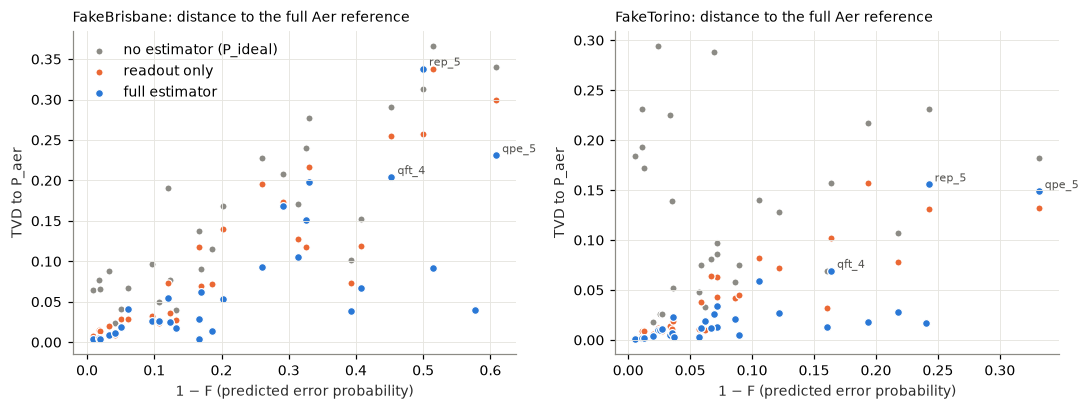

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, bname in zip(axes, CONFIG["backends"]):
    d = rq1[rq1.backend == bname]
    ax.scatter(1 - d.F, d.tvd_ideal_aer, s=22, color=C_GRAY, label="no estimator (P_ideal)", edgecolor="white", linewidth=0.8)
    ax.scatter(1 - d.F, d.tvd_readout_only_aer, s=22, color=C_ORANGE, label="readout only", edgecolor="white", linewidth=0.8)
    ax.scatter(1 - d.F, d.tvd_est_aer, s=26, color=C_BLUE, label="full estimator", edgecolor="white", linewidth=0.8)
    for _, r in d.nlargest(3, "tvd_est_aer").iterrows():
        ax.annotate(r.circuit, (1 - r.F, r.tvd_est_aer), fontsize=7, xytext=(4, 2), textcoords="offset points", color="#52514e")
    ax.set_title(f"{bname}: distance to the full Aer reference", fontsize=9, loc="left")
    ax.set_xlabel("1 − F (predicted error probability)"); ax.set_ylabel("TVD to P_aer")
axes[0].legend(loc="upper left")
plt.tight_layout(); plt.show()

### 10.1 Cost scaling with qubit count

Estimator vs full noisy simulation (exact density matrix, and 8192-shot sampling) on GHZ and mirror circuits of growing width.
The estimator's cost is O(#gates) plus the ideal simulation that testing needs anyway (shown separately).

,family,width,n_2q,F,tvd_est_aer,ideal_ms,estimator_ms,aer_exact_ms,aer_shots_ms
0,ghz,2,1,0.9916,0.0039,0.2868,0.3352,5.1444,7.0629
1,ghz,4,3,0.9289,0.0245,0.2213,0.4737,17.7176,22.0605
2,ghz,6,5,0.8492,0.0829,0.3069,0.6965,40.6351,50.4942
3,ghz,8,7,0.7691,0.1721,0.3840,1.0177,63.5340,70.3711
4,ghz,10,9,0.6854,0.2668,0.5515,1.2404,160.6661,174.1949
5,mirror,2,8,0.9365,0.0141,0.7126,0.8304,9.4950,12.4790
6,mirror,4,34,0.5135,0.1300,1.2436,2.4596,130.0751,50.2100
7,mirror,6,48,0.3830,0.3790,1.6637,3.3851,90.5086,97.8433
8,mirror,8,74,0.2335,0.4904,2.3201,5.0115,123.6224,133.5746
9,mirror,10,112,0.0931,0.6235,3.6698,7.4589,6519.0578,6370.9097


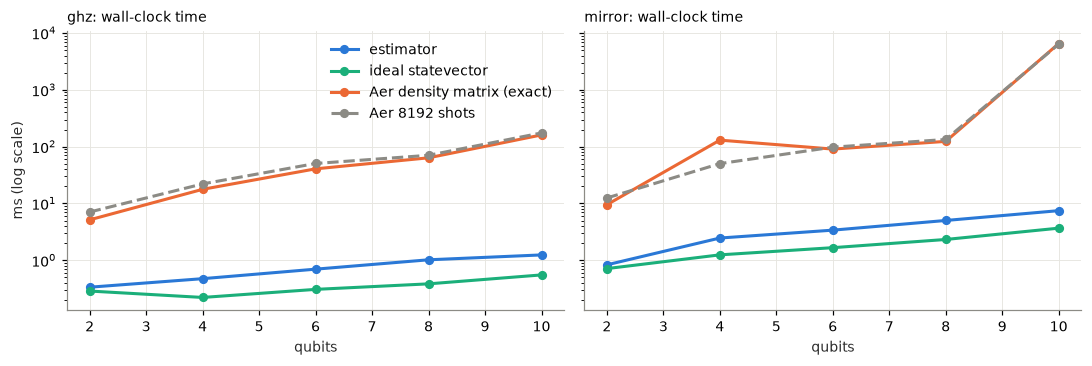

In [16]:
def rq1_scaling(bname="FakeBrisbane", widths=(2, 4, 6, 8, 10)):
    calib, rows = CALIBS[bname], []
    for fam, gen in (("ghz", ghz), ("mirror", lambda w: mirror_circuit(w, 4, seed=7))):
        for w in widths:
            qc = gen(w)
            tqc = PMS[bname].run(qc)
            t0 = time.perf_counter(); p_id = ideal_distribution(qc); t_ideal = time.perf_counter() - t0
            t0 = time.perf_counter(); est = estimate(p_id, tqc, calib); t_est = time.perf_counter() - t0
            t0 = time.perf_counter(); p_aer = reference_distribution(tqc, calib); t_exact = time.perf_counter() - t0
            t0 = time.perf_counter(); reference_distribution(tqc, calib, shots=SHOTS, seed=1); t_shots = time.perf_counter() - t0
            rows.append(dict(family=fam, width=w, n_2q=est.n_2q, F=est.F, tvd_est_aer=tvd(est.p_est, p_aer),
                             ideal_ms=t_ideal * 1e3, estimator_ms=t_est * 1e3, aer_exact_ms=t_exact * 1e3, aer_shots_ms=t_shots * 1e3))
    return pd.DataFrame(rows)


scaling = rq1_scaling()
display(scaling.round(4))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, fam in zip(axes, ("ghz", "mirror")):
    d = scaling[scaling.family == fam]
    ax.plot(d.width, d.estimator_ms, "-o", color=C_BLUE, ms=5, label="estimator")
    ax.plot(d.width, d.ideal_ms, "-o", color=C_AQUA, ms=5, label="ideal statevector")
    ax.plot(d.width, d.aer_exact_ms, "-o", color=C_ORANGE, ms=5, label="Aer density matrix (exact)")
    ax.plot(d.width, d.aer_shots_ms, "--o", color=C_GRAY, ms=5, label="Aer 8192 shots")
    ax.set_yscale("log"); ax.set_xlabel("qubits"); ax.set_title(f"{fam}: wall-clock time", fontsize=9, loc="left")
axes[0].set_ylabel("ms (log scale)"); axes[0].legend()
plt.tight_layout(); plt.show()

## 11. RQ2 — Does an estimator-based threshold separate bugs from noise?

**Protocol (per backend):**
1. Learn τ on the mirror calibration set (Section 9.1). The benchmark circuits are never used for training.
2. For each benchmark circuit and each basis (Z, and X via a Hadamard before measurement):
   * the correct program is run twice: once as the *program under test* (negative example) and once as the known-correct
     reference that only the KL-ratio baseline gets to use;
   * each buggy program is run once (positive example).
3. Compare: KL ratio > 2.0 (fixed), TVD to P_ideal (no estimator), readout-only, gate-only, full estimator (constant and linear τ),
   and the full estimator with the X-basis transformation.

Ground truth: every injected bug is a positive. Some bugs do not change the ideal output at all in a basis (e.g. a Z right
before measurement), so recall is also reported on the bugs that are **observable** (the bug moves the ideal output by
TVD > 0.05 in Z, or in Z or X for the two-basis method).

In [17]:
def detection_dataset(bname, calib):
    """Rows for every (program, basis): correct-under-test (label 0) and buggy (label 1)."""
    rows = []
    for basis in ("Z", "X"):
        tf = x_basis if basis == "X" else (lambda q: q)
        for cname, qc in BENCHMARKS.items():
            cq = tf(qc)
            p_spec = ideal_distribution(cq)
            tqc_c = transpile_cached(("bench", cname, basis), cq, bname)
            # known-correct reference run (KL baseline only) and the correct program under test
            p_ref = reference_distribution(tqc_c, calib, shots=SHOTS, seed=_seed_for(bname, calib.scale, cname, basis, "ref"))
            kl_noise = kl_divergence(p_ref, p_spec)
            row, p_obs = evaluate_program(p_spec, tqc_c, calib, seed=_seed_for(bname, calib.scale, cname, basis, "put"))
            rows.append(dict(backend=bname, scale=calib.scale, basis=basis, circuit=cname, bug_type="none", bug_id=f"{cname}|none",
                             label=0, ideal_shift=0.0, kl_noise=kl_noise, kl_bug=kl_divergence(p_obs, p_spec), **row))
            for (bc, btype, desc, bqc) in BUG_SUITE:
                if bc != cname:
                    continue
                bq = tf(bqc)
                tqc_b = transpile_cached(("bug", cname, btype, desc, basis), bq, bname)
                row, p_obs = evaluate_program(p_spec, tqc_b, calib, seed=_seed_for(bname, calib.scale, cname, desc, basis))
                rows.append(dict(backend=bname, scale=calib.scale, basis=basis, circuit=cname, bug_type=btype,
                                 bug_id=f"{cname}|{btype}|{desc}", label=1,
                                 ideal_shift=tvd(ideal_distribution(bq), p_spec),
                                 kl_noise=kl_noise, kl_bug=kl_divergence(p_obs, p_spec), **row))
    return pd.DataFrame(rows)


def apply_methods(df, th):
    """Add per-method verdict columns (Z-basis rows get the single-basis verdicts)."""
    out = df.copy()
    for (v, mode), t in th.items():
        F = out["F"] if v in ("gate", "full") else np.ones(len(out))
        tau = t(F, out[f"floor_{v}"])
        out[f"tau_{v}_{mode}"] = tau
        out[f"V_{v}_{mode}"] = verdict(out[f"D_{v}"], out[f"U_{v}"], tau)
        out[f"S_{v}_{mode}"] = out[f"D_{v}"] / tau            # score for ROC
    out["V_kl_ratio"], out["S_kl_ratio"] = kl_ratio_verdict(out["kl_noise"], out["kl_bug"])
    return out


def program_level(df):
    """One row per program: Z-basis verdicts + the two-basis (Z ∪ X) verdict of the full estimator."""
    z = df[df.basis == "Z"].set_index("bug_id")
    x = df[df.basis == "X"].set_index("bug_id")
    prog = z.copy()
    for mode in ("constant", "linear"):
        prog[f"V_full_{mode}_ZX"] = combine_bases(z[f"V_full_{mode}"], x.loc[z.index, f"V_full_{mode}"])
        prog[f"S_full_{mode}_ZX"] = np.maximum(z[f"S_full_{mode}"], x.loc[z.index, f"S_full_{mode}"])
    prog["shift_Z"] = z["ideal_shift"]
    prog["shift_ZX"] = np.maximum(z["ideal_shift"], x.loc[z.index, "ideal_shift"])
    return prog.reset_index()


METHODS = [  # (label, verdict column, score column, observability column)
    ("KL ratio > 2.0 (fixed)", "V_kl_ratio", "S_kl_ratio", "shift_Z"),
    ("TVD to P_ideal, learned τ", "V_none_constant", "S_none_constant", "shift_Z"),
    ("readout-only estimator", "V_readout_constant", "S_readout_constant", "shift_Z"),
    ("gate-only estimator (no readout)", "V_gate_constant", "S_gate_constant", "shift_Z"),
    ("full estimator, constant τ", "V_full_constant", "S_full_constant", "shift_Z"),
    ("full estimator, τ(F)", "V_full_linear", "S_full_linear", "shift_Z"),
    ("full estimator, constant τ, Z+X", "V_full_constant_ZX", "S_full_constant_ZX", "shift_ZX"),
    ("full estimator, τ(F), Z+X", "V_full_linear_ZX", "S_full_linear_ZX", "shift_ZX"),
]


def roc_auc(scores, labels):
    """Rank-based AUC (probability a random bug scores above a random correct program)."""
    s, y = np.asarray(scores, float), np.asarray(labels)
    s = np.where(np.isfinite(s), s, np.nanmax(s[np.isfinite(s)]) * 10 if np.isfinite(s).any() else 0)
    ranks = pd.Series(s).rank().to_numpy()
    n1, n0 = (y == 1).sum(), (y == 0).sum()
    return (ranks[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0) if n1 and n0 else np.nan


def metrics_table(prog, obs_cut=CONFIG["observable_tvd"]):
    rows = []
    y = prog["label"].to_numpy()
    for name, vcol, scol, shcol in METHODS:
        flag = prog[vcol].to_numpy() == "BUG"
        tp, fp = int((flag & (y == 1)).sum()), int((flag & (y == 0)).sum())
        fn, tn = int((~flag & (y == 1)).sum()), int((~flag & (y == 0)).sum())
        obs = (y == 1) & (prog[shcol].to_numpy() > obs_cut)
        prec = tp / (tp + fp) if tp + fp else np.nan
        rec = tp / (tp + fn) if tp + fn else np.nan
        rows.append({"method": name, "precision": prec, "recall": rec,
                     "F1": 2 * prec * rec / (prec + rec) if prec and rec else 0.0,
                     "recall (observable bugs)": (flag & obs).sum() / obs.sum() if obs.sum() else np.nan,
                     "false-positive rate": fp / (fp + tn) if fp + tn else np.nan,
                     "inconclusive rate": float((prog[vcol] == "INCONCLUSIVE").mean()),
                     "ROC AUC": roc_auc(prog[scol], y)})
    return pd.DataFrame(rows).set_index("method")


THRESHOLDS, CAL_DFS, DETECT = {}, {}, {}
for bname in CONFIG["backends"]:
    t0 = time.time()
    CAL_DFS[bname] = run_calibration(bname, CALIBS[bname])
    THRESHOLDS[bname] = learn_all_thresholds(CAL_DFS[bname])
    DETECT[bname] = program_level(apply_methods(detection_dataset(bname, CALIBS[bname]), THRESHOLDS[bname]))
    print(f"{bname}: calibration + detection dataset in {time.time() - t0:.0f}s "
          f"({(DETECT[bname].label == 1).sum()} buggy, {(DETECT[bname].label == 0).sum()} correct programs)")
    print(f"   full estimator: constant {THRESHOLDS[bname][('full', 'constant')].describe()} | "
          f"linear {THRESHOLDS[bname][('full', 'linear')].describe()}")

FakeBrisbane: calibration + detection dataset in 42s (318 buggy, 30 correct programs)
   full estimator: constant τ = 0.3611 | linear τ = floor + 0.0051 + 0.3997·(1−F) + 0.0922


FakeTorino: calibration + detection dataset in 60s (318 buggy, 30 correct programs)
   full estimator: constant τ = 0.1861 | linear τ = floor + -0.0056 + 0.4011·(1−F) + 0.0229


In [18]:
for bname in CONFIG["backends"]:
    print(f"\n=== {bname} — detection quality (τ learned on {len(CAL_SET)} mirror circuits, quantile {CONFIG['tau_quantile']}) ===")
    display(metrics_table(DETECT[bname]).round(3))


=== FakeBrisbane — detection quality (τ learned on 60 mirror circuits, quantile 0.95) ===


,precision,recall,F1,recall (observable bugs),false-positive rate,inconclusive rate,ROC AUC
method,,,,,,,
KL ratio > 2.0 (fixed),1.000,0.664,0.798,0.917,0.000,0.394,0.850
"TVD to P_ideal, learned τ",1.000,0.258,0.410,0.357,0.000,0.342,0.856
readout-only estimator,1.000,0.261,0.414,0.361,0.000,0.379,0.864
gate-only estimator (no readout),1.000,0.519,0.683,0.717,0.000,0.210,0.862
"full estimator, constant τ",1.000,0.509,0.675,0.704,0.000,0.210,0.869
"full estimator, τ(F)",0.995,0.588,0.739,0.796,0.033,0.204,0.867
"full estimator, constant τ, Z+X",1.000,0.544,0.705,0.703,0.000,0.172,0.893
"full estimator, τ(F), Z+X",0.995,0.648,0.785,0.821,0.033,0.135,0.893



=== FakeTorino — detection quality (τ learned on 60 mirror circuits, quantile 0.95) ===


,precision,recall,F1,recall (observable bugs),false-positive rate,inconclusive rate,ROC AUC
method,,,,,,,
KL ratio > 2.0 (fixed),1.000,0.667,0.800,0.917,0.000,0.391,0.866
"TVD to P_ideal, learned τ",1.000,0.607,0.755,0.839,0.000,0.138,0.857
readout-only estimator,1.000,0.604,0.753,0.835,0.000,0.138,0.876
gate-only estimator (no readout),0.986,0.670,0.798,0.900,0.100,0.101,0.862
"full estimator, constant τ",1.000,0.648,0.786,0.896,0.000,0.101,0.896
"full estimator, τ(F)",0.996,0.711,0.829,0.961,0.033,0.063,0.887
"full estimator, constant τ, Z+X",1.000,0.670,0.802,0.866,0.000,0.101,0.917
"full estimator, τ(F), Z+X",0.996,0.745,0.853,0.943,0.033,0.063,0.906


### 11.1 How well does τ transfer from the calibration set?

The gaps of correct programs should sit below τ about 95% of the time if the mirror calibration set is representative.
Below: the gap distribution on the calibration set vs on the correct benchmark programs, and the false-positive rate per circuit.

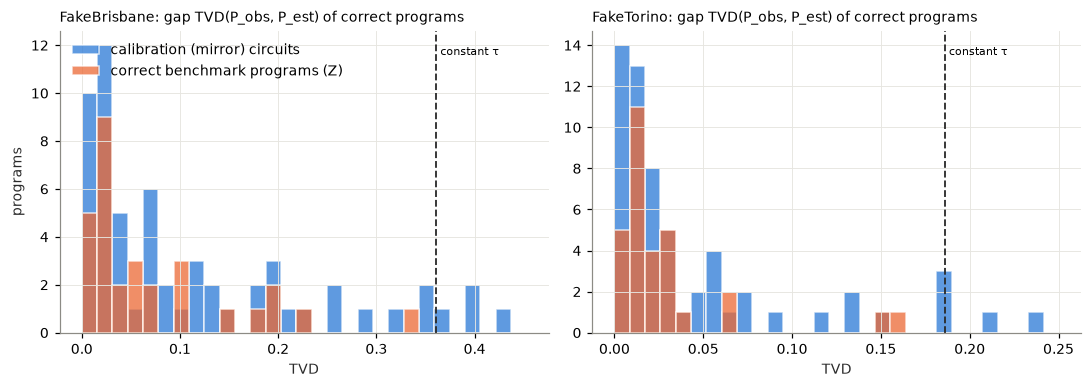

,FakeBrisbane D_full,FakeBrisbane V_full_linear,FakeBrisbane tau_full_linear,FakeTorino D_full,FakeTorino V_full_linear,FakeTorino tau_full_linear
circuit,,,,,,
adder_4,0.106577,NOISE,0.237603,0.028983,NOISE,0.079040
bell_2,0.009384,NOISE,0.106609,0.012564,NOISE,0.026496
bv_3,0.016318,NOISE,0.119854,0.012419,NOISE,0.030573
bv_5,0.042971,NOISE,0.127994,0.022191,NOISE,0.037104
clifford_3,0.020054,INCONCLUSIVE,0.175608,0.008547,INCONCLUSIVE,0.043828
clifford_5,0.042046,INCONCLUSIVE,0.352629,0.029401,INCONCLUSIVE,0.138387
dj_3,0.019003,NOISE,0.119854,0.010068,NOISE,0.029920
dj_5,0.174031,NOISE,0.225303,0.032539,NOISE,0.052974
ghz_3,0.010171,NOISE,0.117689,0.005200,NOISE,0.030884


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, bname in zip(axes, CONFIG["backends"]):
    cal = CAL_DFS[bname]; neg = DETECT[bname][DETECT[bname].label == 0]
    bins = np.linspace(0, max(cal.D_full.max(), neg.D_full.max()) * 1.05, 30)
    ax.hist(cal.D_full, bins=bins, color=C_BLUE, alpha=0.75, label="calibration (mirror) circuits", edgecolor="white", linewidth=1)
    ax.hist(neg.D_full, bins=bins, color=C_ORANGE, alpha=0.75, label="correct benchmark programs (Z)", edgecolor="white", linewidth=1)
    ax.axvline(THRESHOLDS[bname][("full", "constant")].tau0, color="#2b2b2b", lw=1.2, ls="--")
    ax.text(THRESHOLDS[bname][("full", "constant")].tau0, ax.get_ylim()[1] * 0.92, " constant τ", fontsize=7)
    ax.set_title(f"{bname}: gap TVD(P_obs, P_est) of correct programs", fontsize=9, loc="left"); ax.set_xlabel("TVD")
axes[0].legend(); axes[0].set_ylabel("programs")
plt.tight_layout(); plt.show()

fp = pd.concat([DETECT[b][DETECT[b].label == 0].assign(backend=b) for b in CONFIG["backends"]])
fp_table = fp.pivot_table(index="circuit", columns="backend", values=["D_full", "tau_full_linear", "V_full_linear"], aggfunc="first")
fp_table.columns = [f"{b} {m}" for m, b in fp_table.columns]   # flatten (metric, backend) headers
display(fp_table.sort_index(axis=1))

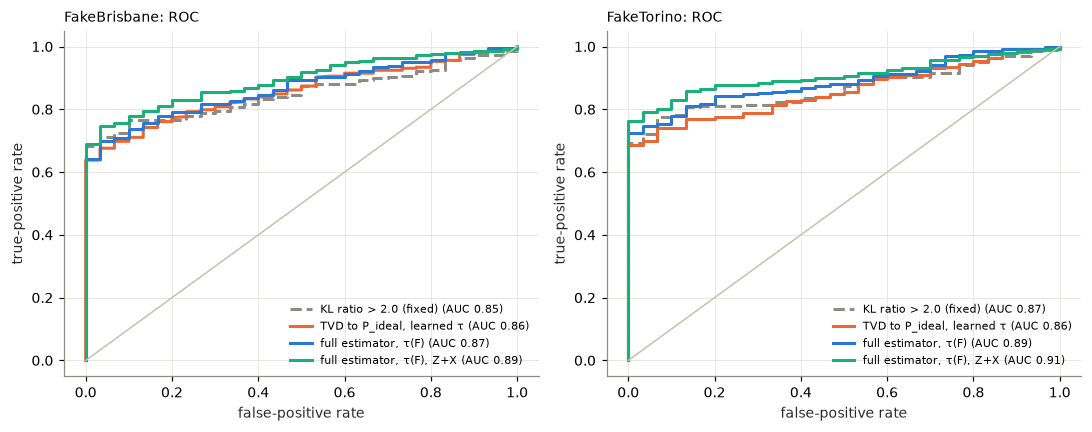

In [20]:
def roc_curve(scores, labels):
    s = np.asarray(scores, float); y = np.asarray(labels)
    s = np.where(np.isfinite(s), s, 1e9)
    thr = np.unique(s)[::-1]
    tpr = [((s >= t) & (y == 1)).sum() / (y == 1).sum() for t in thr]
    fpr = [((s >= t) & (y == 0)).sum() / (y == 0).sum() for t in thr]
    return np.r_[0, fpr, 1], np.r_[0, tpr, 1]


fig, axes = plt.subplots(1, 2, figsize=(10, 4))
show = [("KL ratio > 2.0 (fixed)", C_GRAY, "--"), ("TVD to P_ideal, learned τ", C_ORANGE, "-"),
        ("full estimator, τ(F)", C_BLUE, "-"), ("full estimator, τ(F), Z+X", C_AQUA, "-")]
for ax, bname in zip(axes, CONFIG["backends"]):
    prog = DETECT[bname]
    for name, color, ls in show:
        _, _, scol, _ = next(m for m in METHODS if m[0] == name)
        fpr, tpr = roc_curve(prog[scol], prog["label"])
        ax.plot(fpr, tpr, color=color, ls=ls, lw=2, label=f"{name} (AUC {roc_auc(prog[scol], prog['label']):.2f})")
    ax.plot([0, 1], [0, 1], color="#c3c2b7", lw=1)
    ax.set_title(f"{bname}: ROC", fontsize=9, loc="left"); ax.set_xlabel("false-positive rate"); ax.set_ylabel("true-positive rate")
    ax.legend(fontsize=7, loc="lower right")
plt.tight_layout(); plt.show()

## 12. RQ3 — How does bug type affect detectability under realistic noise?

Same protocol on one backend, with the calibration scaled from 0.5× to 4× the real error rates (τ re-learned at each scale,
as it would be for a different device). Detection rate = fraction of injected bugs flagged by the full estimator with τ(F) using
both bases; the table also shows how many of those bugs are observable at all.

In [21]:
RQ3 = []
bname = CONFIG["rq3_backend"]
for s in CONFIG["noise_scales"]:
    t0 = time.time()
    cal_s = CALIBS[bname].scaled(s)
    if s == 1.0:
        prog = DETECT[bname]
    else:
        th = learn_all_thresholds(run_calibration(bname, cal_s))
        prog = program_level(apply_methods(detection_dataset(bname, cal_s), th))
    RQ3.append(prog.assign(noise_scale=s))
    print(f"noise scale {s}: done in {time.time() - t0:.0f}s")
RQ3 = pd.concat(RQ3, ignore_index=True)

noise scale 0.5: done in 39s
noise scale 1.0: done in 0s


noise scale 2.0: done in 40s


noise scale 4.0: done in 41s


In [22]:
bugs3 = RQ3[RQ3.label == 1].copy()
bugs3["detected"] = bugs3["V_full_linear_ZX"] == "BUG"
bugs3["detected_Z"] = bugs3["V_full_linear"] == "BUG"
bugs3["observable_ZX"] = bugs3["shift_ZX"] > CONFIG["observable_tvd"]
rate = bugs3.pivot_table(index="bug_type", columns="noise_scale", values="detected", aggfunc="mean")
rate_z = bugs3.pivot_table(index="bug_type", columns="noise_scale", values="detected_Z", aggfunc="mean")
obs = bugs3[bugs3.noise_scale == 1.0].groupby("bug_type")["observable_ZX"].mean().rename("observable (Z or X)")
fpr3 = RQ3[RQ3.label == 0].groupby("noise_scale")["V_full_linear_ZX"].apply(lambda v: (v == "BUG").mean()).rename("FPR")
print("Detection rate, full estimator + τ(F), Z+X bases (rows: bug type, columns: noise scale)")
display(rate.join(obs).round(2))
print("Same, Z basis only")
display(rate_z.round(2))
print("False-positive rate on correct programs by noise scale")
display(fpr3.to_frame().T.round(3))

Detection rate, full estimator + τ(F), Z+X bases (rows: bug type, columns: noise scale)


,0.5,1.0,2.0,4.0,observable (Z or X)
bug_type,,,,,
bit_flip,0.67,0.58,0.47,0.30,0.68
missing_gate,0.88,0.82,0.60,0.42,0.92
missing_reset,1.00,1.00,0.00,0.00,1.00
phase_flip,0.58,0.52,0.37,0.18,0.58
wrong_angle,0.04,0.00,0.00,0.00,0.28
wrong_gate,0.90,0.78,0.60,0.38,0.95
wrong_wiring,0.88,0.82,0.63,0.43,0.96


Same, Z basis only


noise_scale,0.5,1.0,2.0,4.0
bug_type,,,,
bit_flip,0.67,0.57,0.47,0.30
missing_gate,0.88,0.80,0.58,0.38
missing_reset,1.00,1.00,0.00,0.00
phase_flip,0.45,0.37,0.28,0.15
wrong_angle,0.00,0.00,0.00,0.00
wrong_gate,0.90,0.72,0.58,0.38
wrong_wiring,0.88,0.75,0.61,0.41


False-positive rate on correct programs by noise scale


noise_scale,0.5,1.0,2.0,4.0
FPR,0.033,0.033,0.0,0.0


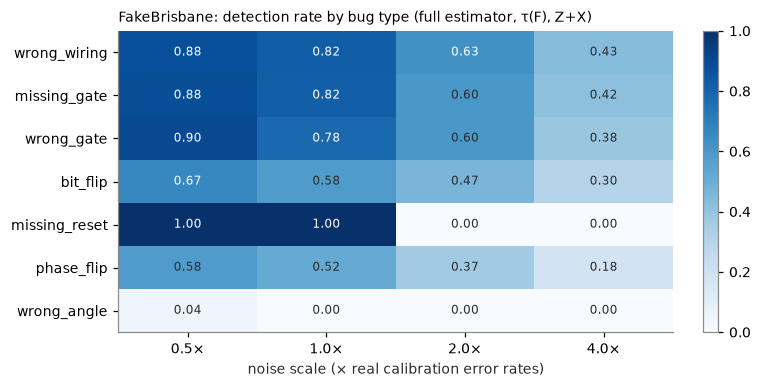

size,small,medium,large
bug_type,,,
bit_flip,0.65,0.70,0.40
missing_gate,1.00,0.85,0.60
missing_reset,NaN,NaN,1.00
phase_flip,0.60,0.50,0.45
wrong_angle,0.00,0.00,0.00
wrong_gate,1.00,0.80,0.55
wrong_wiring,1.00,0.88,0.56


In [23]:
fig, ax = plt.subplots(figsize=(7, 3.6))
order = rate.mean(axis=1).sort_values(ascending=False).index
im = ax.imshow(rate.loc[order].to_numpy(), cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(rate.columns)), [f"{c}×" for c in rate.columns]); ax.set_yticks(range(len(order)), order)
ax.set_xlabel("noise scale (× real calibration error rates)"); ax.grid(False)
for i, bt in enumerate(order):
    for j, c in enumerate(rate.columns):
        v = rate.loc[bt, c]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > 0.6 else "#2b2b2b")
ax.set_title(f"{bname}: detection rate by bug type (full estimator, τ(F), Z+X)", fontsize=9, loc="left")
fig.colorbar(im, ax=ax, fraction=0.03)
plt.tight_layout(); plt.show()

# by circuit size class at the real noise level
sizes = rq1[rq1.backend == bname].set_index("circuit")["size"]
b1 = bugs3[bugs3.noise_scale == 1.0].assign(size=lambda d: d.circuit.map(sizes))
display(b1.pivot_table(index="bug_type", columns="size", values="detected", aggfunc="mean", observed=True).round(2))

## 13. Findings

These numbers come from fake backends, with the full Aer simulation standing in for hardware. Real devices add crosstalk and drift, so treat them as a best case.

- Estimator vs full simulation: median TVD 0.039 (Brisbane) and 0.013 (Torino), compared with about 0.10 when P_ideal is used directly. The estimator takes about 1 ms per circuit; exact Aer takes 27–45 ms, and 4.7 s at 10 qubits (estimator: 6 ms).
- The estimate is weakest on deep circuits on Brisbane (`rep_5`, `qpe_5`, `qft_4`, `mirror_5`, TVD 0.2–0.34). Global depolarizing is too coarse there. In `rep_5` the mid-circuit reset clears earlier ancilla errors, which the model cannot represent.
- Converting ε to ε(d+1)/d made the fit worse on both backends, so the spec's (1 − ε) is kept.
- Detection with τ learned only on mirror circuits: F1 0.79 / 0.85 with τ(F) and both bases, 0.41 / 0.76 without the estimator, and 0.80 / 0.80 for the KL-ratio rule, which needs a known-correct run to compare against.
- τ(F) gives higher recall than a constant τ at almost the same precision. Adding the X basis lifts phase-flip detection from 0.37 to 0.52.
- False positives: 1 of 30 correct programs per backend; on Brisbane it is `rep_5`.
- By bug type at real noise: wrong gate, wrong wiring and missing gate are caught about 80% of the time. Bit and phase flips are caught 58% and 52% of the time, close to the share of them that changes the ideal output at all (68% and 58%). Wrong-angle bugs (0.15 rad) are not caught. Everything drops to about 40% at 4× noise.

## 14. Real IBM hardware (opt-in)

⚠ **New jobs are submitted only when `RUN_HARDWARE = True`** (Section 0), one per device in `HW_NEW_DEVICES`. Finished jobs listed in `HW_JOB_IDS` are reloaded from IBM, which uses no QPU time.

Plan (spec §7 validation step 2): the same 66-circuit job on three devices (ibm_kingston, ibm_fez, ibm_marrakesh) on three different days.
Each job has 12 mirror circuits for learning τ, plus 7 programs × 2 bases × (1 correct + 3 bugs), 8192 shots each.

For every job the section:
1. prints QPU time used and remaining on the instance, and the QPU seconds charged to each job;
2. re-reads the device calibration right before submission and saves it as `hw_calibration_<job id>.json`;
3. runs exactly the transpiled circuits `tqc` that the estimator uses;
4. learns τ on that job's own mirror circuits and gives verdicts.

To save the account once (the token is not stored in this notebook):
`QiskitRuntimeService.save_account(name="quantum-oracle", channel="ibm_quantum_platform", token="...")`

In [24]:
# ── Hardware settings and helpers ───────────────────────────────────────────
HW_ACCOUNT  = "quantum-oracle"   # account saved with QiskitRuntimeService.save_account(name=...)
HW_INSTANCE = "research"         # instance approved for this project

# Finished jobs: reloaded on every run of this notebook, no QPU time used.
HW_JOB_IDS = [
    "dbl3mg0nceqs73amva20",      # day 1 (2026-11-03), ibm_kingston, 144 s QPU
    "dbl4jrhkdqps7393iik0",      # day 1 (2026-11-03), ibm_fez, 143 s QPU
    "dbl4js1kdqps7393iim0",      # day 1 (2026-11-03), ibm_marrakesh, 146 s QPU
    "dbmf5ad8mdtc73d7s1e0",      # day 2 (2026-11-05), ibm_kingston, 144 s QPU
    "dbmf5b58mdtc73d7s1fg",      # day 2 (2026-11-05), ibm_fez, 143 s QPU
    "dbmf5be74qds73ds6jpg",      # day 2 (2026-11-05), ibm_marrakesh, 146 s QPU
]
# Devices that get a NEW job when RUN_HARDWARE = True (afterwards, add the printed ids to HW_JOB_IDS).
HW_NEW_DEVICES = ["ibm_kingston", "ibm_fez", "ibm_marrakesh"]

HW_CIRCUITS = ["bell_2", "ghz_3", "bv_3", "grover_2", "qft_3", "adder_4", "rep_5"]
HW_BUGS     = ["bit_flip", "wrong_wiring", "missing_gate"]
HW_MIRRORS  = [k for k in CAL_SET if k.endswith("_s0")][:12]


def connect_ibm(attempts=4, wait_s=15):
    """Connect to IBM Quantum; retry because the login service occasionally fails transiently."""
    from qiskit_ibm_runtime import QiskitRuntimeService
    for k in range(attempts):
        try:
            return QiskitRuntimeService(name=HW_ACCOUNT, instance=HW_INSTANCE)
        except Exception as exc:
            if k == attempts - 1:
                raise
            print(f"connection attempt {k + 1} failed ({exc}); retrying in {wait_s} s")
            time.sleep(wait_s)


def usage_report(service, label):
    """Print and return (used, remaining) QPU seconds for the instance."""
    u = service.usage()
    used = float(u.get("usage_consumed_seconds") or 0.0)
    rem = u.get("usage_remaining_seconds")
    if rem is None and u.get("usage_allocation_seconds") is not None:
        rem = float(u["usage_allocation_seconds"]) - used
    print(f"[{label}] instance '{HW_INSTANCE}': used {used:.0f} s | remaining {rem:.0f} s"
          + (f" of {float(u['usage_allocation_seconds']):.0f} s" if u.get("usage_allocation_seconds") else ""))
    return used, rem


def hardware_items():
    """(kind, name, label, basis, logical circuit, expected distribution) for every circuit of a job, in job order."""
    items = [("cal", k, 0, "Z", CAL_SET[k], ideal_distribution(CAL_SET[k])) for k in HW_MIRRORS]
    for c in HW_CIRCUITS:
        first_bug = {bt: next(d for (b2, t2, d, _) in BUG_SUITE if b2 == c and t2 == bt)
                     for bt in HW_BUGS if any(b2 == c and t2 == bt for (b2, t2, _, _) in BUG_SUITE)}
        for basis, tf in (("Z", lambda q: q), ("X", x_basis)):
            p_spec = ideal_distribution(tf(BENCHMARKS[c]))
            items.append(("test", f"{c}|none", 0, basis, tf(BENCHMARKS[c]), p_spec))
            for (bc, bt, desc, bqc) in BUG_SUITE:
                if bc == c and first_bug.get(bt) == desc:
                    items.append(("test", f"{c}|{bt}|{desc}", 1, basis, tf(bqc), p_spec))
    return items


def submit_job(service, backend_name):
    """Transpile for the device, re-read its calibration, submit one SamplerV2 job (does not wait)."""
    from qiskit_ibm_runtime import SamplerV2 as Sampler
    backend = service.backend(backend_name)
    pm_hw = make_pass_manager(backend)
    tqcs = [pm_hw.run(it[4]) for it in hardware_items()]
    calib = read_calibration(backend)                                # re-read right before submission
    job = Sampler(mode=backend).run(tqcs, shots=SHOTS)
    save_calibration(calib, f"hw_calibration_{job.job_id()}.json")
    print(f"submitted {job.job_id()} to {backend_name}: {len(tqcs)} circuits x {SHOTS} shots "
          f"(pending jobs {backend.status().pending_jobs}, calibration {calib.timestamp})")
    return job


def analyse_hardware(items, tqcs, pub_results, calib, shots, job_id, backend_name):
    """Estimator + verdicts for every circuit of the job; τ learned on the job's own mirror circuits."""
    rows = []
    for it, tqc, pub in zip(items, tqcs, pub_results):
        creg = next(iter(pub.data.keys()))
        p_hw = counts_to_probs(pub.data[creg].get_counts(), tqc.num_clbits)
        row, _ = evaluate_program(it[5], tqc, calib, shots=shots, p_obs=p_hw)
        rows.append(dict(kind=it[0], program=it[1], circuit=it[1].split("|")[0], bug_type=(it[1].split("|") + ["none"])[1],
                         ideal_shift=tvd(ideal_distribution(it[4]), it[5]),
                         label=it[2], basis=it[3], backend=backend_name, calibration=calib.timestamp, job_id=job_id, **row))
    df = pd.DataFrame(rows)
    cal = df[df.kind == "cal"]
    th = {mode: learn_threshold(cal.D_full, cal.F, cal.floor_full, mode, CONFIG["tau_quantile"]) for mode in ("constant", "linear")}
    th_none = learn_threshold(cal.D_none, np.ones(len(cal)), cal.floor_none, "constant", CONFIG["tau_quantile"])
    test = df[df.kind == "test"].copy()
    for mode, t in th.items():
        test[f"tau_{mode}"] = t(test.F, test.floor_full)
        test[f"V_{mode}"] = verdict(test.D_full, test.U_full, test[f"tau_{mode}"])
    test["V_none"] = verdict(test.D_none, test.U_none, th_none(np.ones(len(test)), test.floor_none))
    return df, test, th, th_none


def load_run(service, job_id):
    """Fetch a finished job (no QPU time), rebuild its circuits and calibration, and analyse it."""
    job = service.job(job_id)
    result = job.result()
    tqcs = [p[0] if isinstance(p, (tuple, list)) else getattr(p, "circuit", p) for p in job.inputs["pubs"]]
    calib = load_calibration(f"hw_calibration_{job_id}.json")
    m = job.metrics()
    usage, ts = m.get("usage") or {}, m.get("timestamps") or {}
    backend_name = job.backend().name
    df, test, th, th_none = analyse_hardware(hardware_items(), tqcs, result, calib, SHOTS, job_id, backend_name)
    return dict(job_id=job_id, backend=backend_name, created=ts.get("created", "")[:19],
                finished=ts.get("finished", "")[:19], qpu_s=usage.get("qpu_charge_time_seconds", usage.get("quantum_seconds")),
                calib=calib, df=df, test=test, th=th, th_none=th_none)


def verdict_table(run):
    """One row per program: Z, X and two-basis verdicts (τ(F)), plus the no-estimator verdict."""
    t = run["test"].set_index(["program", "basis"])
    rows = []
    for prog in run["test"].program.unique():
        z, x = t.loc[(prog, "Z")], t.loc[(prog, "X")]
        rows.append({"program": prog, "is bug": bool(z.label),
                     "changes ideal output": bool(max(z.ideal_shift, x.ideal_shift) > CONFIG["observable_tvd"]),
                     "F (Z)": z.F, "D (Z)": z.D_full, "τ(F) (Z)": z.tau_linear, "verdict Z": z.V_linear,
                     "D (X)": x.D_full, "verdict X": x.V_linear,
                     "verdict Z+X": combine_bases([z.V_linear], [x.V_linear])[0],
                     "no-estimator Z+X": combine_bases([z.V_none], [x.V_none])[0]})
    return pd.DataFrame(rows).set_index("program")

In [25]:
# ── Submit new jobs (only if RUN_HARDWARE) and reload all finished jobs ────────
hw_runs = []
if RUN_HARDWARE or HW_JOB_IDS:
    service = connect_ibm()
    used_before, rem_before = usage_report(service, "before")
    if RUN_HARDWARE:
        new_jobs = [submit_job(service, dev) for dev in HW_NEW_DEVICES]
        t_wait = time.time()
        for j in new_jobs:
            j.result()
        print(f"all new jobs finished after {time.time() - t_wait:.0f} s")
        new_ids = [j.job_id() for j in new_jobs]
        HW_JOB_IDS = HW_JOB_IDS + [i for i in new_ids if i not in HW_JOB_IDS]
        print("NEW job ids, add them to HW_JOB_IDS and set RUN_HARDWARE = False:", new_ids)
    for jid in HW_JOB_IDS:
        r = load_run(service, jid)
        hw_runs.append(r)
        print(f"{jid}: {r['backend']:14s} created {r['created']}Z | QPU charged {r['qpu_s']} s | calibration {r['calib'].timestamp}")
    used_after, rem_after = usage_report(service, "after")
    print(f"QPU time of the {len(hw_runs)} jobs above: {sum(r['qpu_s'] or 0 for r in hw_runs)} s")
    if RUN_HARDWARE:
        print(f"Instance counter change during this run: {used_after - used_before:.0f} s (can lag a few minutes)")
else:
    print("RUN_HARDWARE is False and HW_JOB_IDS is empty: nothing to do (no QPU time used).")

[before] instance 'research': used 4046 s | remaining 6754 s of 10800 s


dbl3mg0nceqs73amva20: ibm_kingston   created 2026-11-03T19:51:28Z | QPU charged 144 s | calibration 2026-11-03T13:41:41-06:00


dbl4jrhkdqps7393iik0: ibm_fez        created 2026-11-03T20:54:06Z | QPU charged 143 s | calibration 2026-11-03T14:41:44-06:00


dbl4js1kdqps7393iim0: ibm_marrakesh  created 2026-11-03T20:54:08Z | QPU charged 146 s | calibration 2026-11-03T14:13:41-06:00


dbmf5ad8mdtc73d7s1e0: ibm_kingston   created 2026-11-05T21:18:33Z | QPU charged 144 s | calibration 2026-11-05T14:58:22-06:00


dbmf5b58mdtc73d7s1fg: ibm_fez        created 2026-11-05T21:18:36Z | QPU charged 143 s | calibration 2026-11-05T14:58:05-06:00


dbmf5be74qds73ds6jpg: ibm_marrakesh  created 2026-11-05T21:18:37Z | QPU charged 146 s | calibration 2026-11-05T15:10:02-06:00


[after] instance 'research': used 4046 s | remaining 6754 s of 10800 s
QPU time of the 6 jobs above: 866 s


### 14.1 Hardware results

One row per job: how close the estimate is to the real output on known-correct circuits, the thresholds learned on that job's mirror circuits, and the detection counts. Then the gap on correct circuits for all jobs, and the two-basis verdicts per program and device.

,device,date (UTC),QPU s,gap est. (mirrors),gap est. (correct progs),gap no-est. (mirrors),gap no-est. (correct progs),τ est.,τ no-est.,observable bugs caught,false alarms
job,,,,,,,,,,,
dbl3mg0nceqs73amva20,ibm_kingston,2026-11-03,144,0.0336,0.0249,0.0745,0.0466,0.0587,0.1443,17/17,1/7
dbl4jrhkdqps7393iik0,ibm_fez,2026-11-03,143,0.0479,0.0246,0.1168,0.0524,0.1030,0.2277,17/17,0/7
dbl4js1kdqps7393iim0,ibm_marrakesh,2026-11-03,146,0.0941,0.0591,0.0898,0.0588,0.1464,0.2361,17/17,2/7
dbmf5ad8mdtc73d7s1e0,ibm_kingston,2026-11-05,144,0.0379,0.0341,0.0809,0.0482,0.0444,0.1448,17/17,3/7
dbmf5b58mdtc73d7s1fg,ibm_fez,2026-11-05,143,0.0457,0.0291,0.1127,0.0555,0.0762,0.1950,17/17,1/7
dbmf5be74qds73ds6jpg,ibm_marrakesh,2026-11-05,146,0.1016,0.0551,0.1431,0.0822,0.4302,0.5253,15/17,0/7


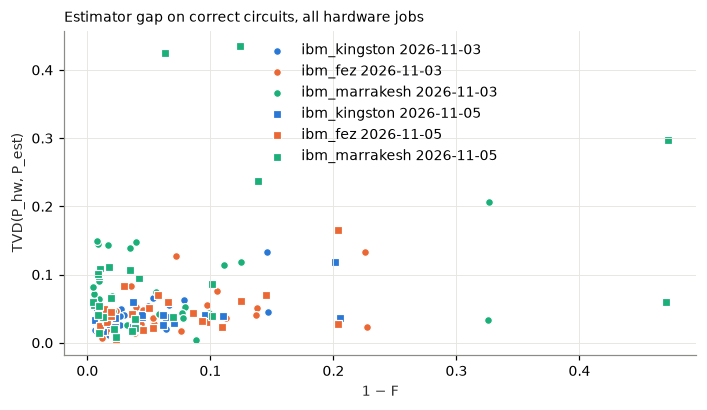

,is bug,changes ideal output,D (Z) ibm_kingston 2026-11-03,verdict ibm_kingston 2026-11-03,D (Z) ibm_fez 2026-11-03,verdict ibm_fez 2026-11-03,D (Z) ibm_marrakesh 2026-11-03,verdict ibm_marrakesh 2026-11-03,D (Z) ibm_kingston 2026-11-05,verdict ibm_kingston 2026-11-05,D (Z) ibm_fez 2026-11-05,verdict ibm_fez 2026-11-05,D (Z) ibm_marrakesh 2026-11-05,verdict ibm_marrakesh 2026-11-05
program,,,,,,,,,,,,,,
bell_2|none,False,False,0.031,NOISE,0.017,NOISE,0.072,NOISE,0.034,NOISE,0.020,NOISE,0.056,NOISE
bell_2|bit_flip|X on q0 at position 2,True,True,0.947,BUG,0.889,BUG,0.864,BUG,0.937,BUG,0.878,BUG,0.869,BUG
bell_2|missing_gate|dropped cx #1,True,True,0.495,BUG,0.471,BUG,0.411,BUG,0.496,BUG,0.459,BUG,0.510,BUG
bell_2|wrong_wiring|swapped wiring of cx #1,True,True,0.495,BUG,0.471,BUG,0.418,BUG,0.496,BUG,0.458,BUG,0.510,BUG
ghz_3|none,False,False,0.024,NOISE,0.018,NOISE,0.099,NOISE,0.048,BUG,0.034,NOISE,0.098,NOISE
ghz_3|bit_flip|X on q0 at position 1,True,False,0.027,NOISE,0.026,NOISE,0.100,NOISE,0.042,NOISE,0.038,NOISE,0.094,NOISE
ghz_3|missing_gate|dropped cx #1,True,True,0.495,BUG,0.483,BUG,0.501,BUG,0.497,BUG,0.478,BUG,0.515,BUG
ghz_3|wrong_wiring|swapped wiring of cx #1,True,True,0.495,BUG,0.486,BUG,0.503,BUG,0.498,BUG,0.481,BUG,0.516,BUG
bv_3|none,False,False,0.017,NOISE,0.028,NOISE,0.046,NOISE,0.012,NOISE,0.005,NOISE,0.008,NOISE


In [26]:
if hw_runs:
    summary_rows = []
    for r in hw_runs:
        d, v = r["df"], verdict_table(r)
        correct = d[d.label == 0]
        y, obs = v["is bug"], v["is bug"] & v["changes ideal output"]
        flag = v["verdict Z+X"] == "BUG"
        summary_rows.append({
            "job": r["job_id"], "device": r["backend"], "date (UTC)": r["created"][:10], "QPU s": r["qpu_s"],
            "gap est. (mirrors)": d[d.kind == "cal"].D_full.median(), "gap est. (correct progs)": correct[correct.kind == "test"].D_full.median(),
            "gap no-est. (mirrors)": d[d.kind == "cal"].D_none.median(), "gap no-est. (correct progs)": correct[correct.kind == "test"].D_none.median(),
            "τ est.": r["th"]["constant"].tau0, "τ no-est.": r["th_none"].tau0,
            "observable bugs caught": f"{int((flag & obs).sum())}/{int(obs.sum())}",
            "false alarms": f"{int((flag & ~y).sum())}/{int((~y).sum())}"})
    display(pd.DataFrame(summary_rows).set_index("job").round(4))

    dev_color = {"ibm_kingston": C_BLUE, "ibm_fez": C_ORANGE, "ibm_marrakesh": C_AQUA}
    days = sorted({r["created"][:10] for r in hw_runs})
    markers = ["o", "s", "^", "D"]
    fig, ax = plt.subplots(figsize=(6.5, 3.8))
    for r in hw_runs:
        c = r["df"][r["df"].label == 0]
        ax.scatter(1 - c.F, c.D_full, s=26, color=dev_color.get(r["backend"], C_GRAY), marker=markers[days.index(r["created"][:10]) % 4],
                   edgecolor="white", linewidth=0.8, label=f"{r['backend']} {r['created'][:10]}")
    ax.set_xlabel("1 − F"); ax.set_ylabel("TVD(P_hw, P_est)"); ax.legend()
    ax.set_title("Estimator gap on correct circuits, all hardware jobs", fontsize=9, loc="left")
    plt.tight_layout(); plt.show()

    tables = {f"{r['backend']} {r['created'][:10]}": verdict_table(r) for r in hw_runs}
    first = next(iter(tables.values()))
    cross = first[["is bug", "changes ideal output"]].copy()
    for name, v in tables.items():
        cross[f"D (Z) {name}"] = v["D (Z)"]
        cross[f"verdict {name}"] = v["verdict Z+X"]
    display(cross.round(3))

### 14.2 Threshold per job vs pooled per device

Each job learns τ from only 12 mirror circuits, so its 95th percentile is close to the single largest gap and moves a lot between jobs. Below, τ is instead pooled over all mirror circuits of the same device (all days), and both versions are scored with the same constant-τ rule. The second table shows which mirror circuits drive τ.

In [27]:
def _hw_counts(run, tau):
    """Two-basis verdicts of one job with a constant τ: (observable bugs caught, false alarms) as strings."""
    t, v = run["test"].set_index(["program", "basis"]), verdict_table(run)
    flag = []
    for prog in v.index:
        vz = verdict([t.loc[(prog, "Z")].D_full], [t.loc[(prog, "Z")].U_full], [tau])[0]
        vx = verdict([t.loc[(prog, "X")].D_full], [t.loc[(prog, "X")].U_full], [tau])[0]
        flag.append(combine_bases([vz], [vx])[0] == "BUG")
    flag, y = np.array(flag), v["is bug"].to_numpy()
    obs = y & v["changes ideal output"].to_numpy()
    return f"{int((flag & obs).sum())}/{int(obs.sum())}", f"{int((flag & ~y).sum())}/{int((~y).sum())}"


if hw_runs:
    rows = []
    for dev in sorted({r["backend"] for r in hw_runs}):
        rs = [r for r in hw_runs if r["backend"] == dev]
        pooled = pd.concat([r["df"][r["df"].kind == "cal"] for r in rs])
        tau_pooled = float(np.quantile(pooled.D_full, CONFIG["tau_quantile"]))
        for r in rs:
            tau_job = r["th"]["constant"].tau0
            (b_job, f_job), (b_pool, f_pool) = _hw_counts(r, tau_job), _hw_counts(r, tau_pooled)
            rows.append({"device": dev, "date": r["created"][:10], "τ per job": tau_job, "bugs (per job)": b_job, "false alarms (per job)": f_job,
                         f"τ pooled ({len(pooled)} mirrors)": tau_pooled, "bugs (pooled)": b_pool, "false alarms (pooled)": f_pool})
    display(pd.DataFrame(rows).set_index(["device", "date"]).round(3))
    gaps = pd.DataFrame({f"{r['backend']} {r['created'][:10]}": r["df"][r["df"].kind == "cal"].set_index("program").D_full for r in hw_runs})
    print("TVD(P_hw, P_est) of every mirror circuit, per job")
    display(gaps.round(3))

τ per job bugs (per job) false alarms (per job)  \
device        date                                                          
ibm_fez       2026-11-03      0.103          17/17                    1/7   
              2026-11-05      0.076          17/17                    1/7   
ibm_kingston  2026-11-03      0.059          17/17                    2/7   
              2026-11-05      0.044          17/17                    3/7   
ibm_marrakesh 2026-11-03      0.146          17/17                    2/7   
              2026-11-05      0.430          17/17                    0/7   

                          τ pooled (24 mirrors) bugs (pooled)  \
device        date                                              
ibm_fez       2026-11-03                  0.084         17/17   
              2026-11-05                  0.084         17/17   
ibm_kingston  2026-11-03                  0.055         17/17   
              2026-11-05                  0.055         17/17   
ibm_marrakesh 2026-11-03                  0.397         17/17   
              2026-11-05                  0.397         17/17   

                         false alarms (pooled)  
device        date                              
ibm_fez       2026-11-03                   1/7  
              2026-11-05                   1/7  
ibm_kingston  2026-11-03                   2/7  
              2026-11-05                   1/7  
ibm_marrakesh 2026-11-03                   0/7  
              2026-11-05                   0/7

TVD(P_hw, P_est) of every mirror circuit, per job


,ibm_kingston 2026-11-03,ibm_fez 2026-11-03,ibm_marrakesh 2026-11-03,ibm_kingston 2026-11-05,ibm_fez 2026-11-05,ibm_marrakesh 2026-11-05
program,,,,,,
mirror_w2_l1_s0,0.031,0.047,0.145,0.039,0.011,0.014
mirror_w2_l2_s0,0.026,0.053,0.143,0.037,0.042,0.111
mirror_w2_l4_s0,0.025,0.127,0.140,0.038,0.060,0.107
mirror_w2_l6_s0,0.020,0.075,0.148,0.038,0.031,0.096
mirror_w3_l1_s0,0.013,0.017,0.065,0.017,0.010,0.108
mirror_w3_l2_s0,0.012,0.084,0.068,0.027,0.083,0.065
mirror_w3_l4_s0,0.049,0.027,0.074,0.021,0.022,0.022
mirror_w3_l6_s0,0.054,0.017,0.043,0.030,0.032,0.038
mirror_w4_l1_s0,0.037,0.032,0.026,0.048,0.049,0.038


### 14.3 Hardware findings (days 1 and 2: 2026-11-03 and 2026-11-05)

Six jobs, one per device per day, 66 circuits × 8192 shots each, 143–146 s of QPU time each (866 s in total).

| Median gap on correct programs | kingston | fez | marrakesh |
|---|---|---|---|
| with estimator, day 1 / day 2 | 0.025 / 0.034 | 0.025 / 0.029 | 0.059 / 0.055 |
| without estimator, day 1 / day 2 | 0.047 / 0.048 | 0.052 / 0.056 | 0.059 / 0.082 |

- **The estimator helps on kingston and fez, consistently on both days.** The gap to the real output is about half of what the ideal distribution gives, and τ is less than half as large.
- **Marrakesh is poorly described by its calibration on both days, in different places.** On day 1 all 2-qubit mirror circuits were off by about 0.14. On day 2 those were fine, but the 4-qubit ones with 2 or more layers were off by 0.24–0.44. The day-2 job ran right after its calibration was read (empty queue), so drift while waiting is not the explanation. Some qubits or couplers in the chosen layout behave worse than their published numbers (spec §6: crosstalk, two-level-system defects). The estimator cannot see this, so on marrakesh it is no better than using P_ideal.
- **τ learned from 12 mirror circuits per job is unstable**: kingston 0.059 → 0.044, and marrakesh 0.146 → 0.430. With τ(F), the low kingston τ caused 3 false alarms on day 2, and the high marrakesh τ missed 2 of 17 real bugs. Pooling all 24 mirror circuits of a device (§14.2) gives one steadier τ per device. With it, all 17 observable bugs were caught on every device and day, with 0–2 false alarms out of 7.
- **`rep_5` (mid-circuit reset) is the recurring false alarm** on every device, as on the simulator.
- The 3 injected bugs that do not change the ideal output (an X on a GHZ qubit right after its Hadamard, an X in `qft_3`, one rewiring in `rep_5`) cannot be told apart from correct programs, as expected.
- Every bug here moves the output by 0.12–0.98 TVD, so all rules catch the same bugs. The estimator's smaller τ matters for subtler bugs (RQ2, simulator).
- Day 3 will show whether these per-device patterns hold, and gives a third set of mirror circuits for the pooled τ.